# DASCM 2026 — Project Part 1
## Port Logistics Dispatching — Exploratory Data Analysis (Classification)

**Course:** Data Analytics in Supply Chain Management  
**Semester:** Fall 2026  
**Dataset:** Port Logistics Dispatching  
**Task:** Exploratory Data Analysis and brainstorming for the six-class target `Recommended_Dispatch_Action`

### Scenario
A port-logistics control tower must respond to changing operating conditions such as traffic congestion, terminal incidents, slot risk, driver-hour constraints, weather, and vehicle technical warnings. The dispatcher must quickly decide what action to take next.

### Analytical task
The dataset is designed to support prediction of:

- `PROCEED_AS_PLANNED`
- `WAIT_AND_MONITOR`
- `RESCHEDULE_SLOT`
- `REROUTE`
- `REASSIGN_VEHICLE`
- `PRIORITY_RECOVERY`

This notebook focuses on **Part 1 EDA only**. It does not train a final classification model. The objective is to understand the dataset, variables, missingness, distributions, outliers, class structure, relationships, and operational hypotheses that can guide the later modeling stage.

### Grading coverage
This notebook explicitly covers:
1. Dataset dimensions and basic statistical features
2. Data types and null-value detection
3. Categorical analysis
4. Numerical analysis: histograms/KDE, box plots, violin plots
5. Outlier detection
6. Relationships: correlation heatmap, pair plot, parallel coordinates, bubble chart
7. Additional operational plots
8. Brainstorming with evidence-linked findings, hypotheses, and questions
9. External methodological references


## 1. Project framing and visual context

The supplied project figure emphasizes four operational dimensions:

- **Terminal congestion:** queue length and yard occupancy
- **Weather and disruptions:** storms, incidents, and delay conditions
- **Time window:** slot, ETA, and delay risk
- **Route conditions:** travel time and congestion

The dataset extends these ideas with operational state variables such as customs status, vehicle technical status, driver hours, alternative resources/routes, service-level penalty, and historical route reliability.

The figure is reproduced below when the notebook is run in the project folder.

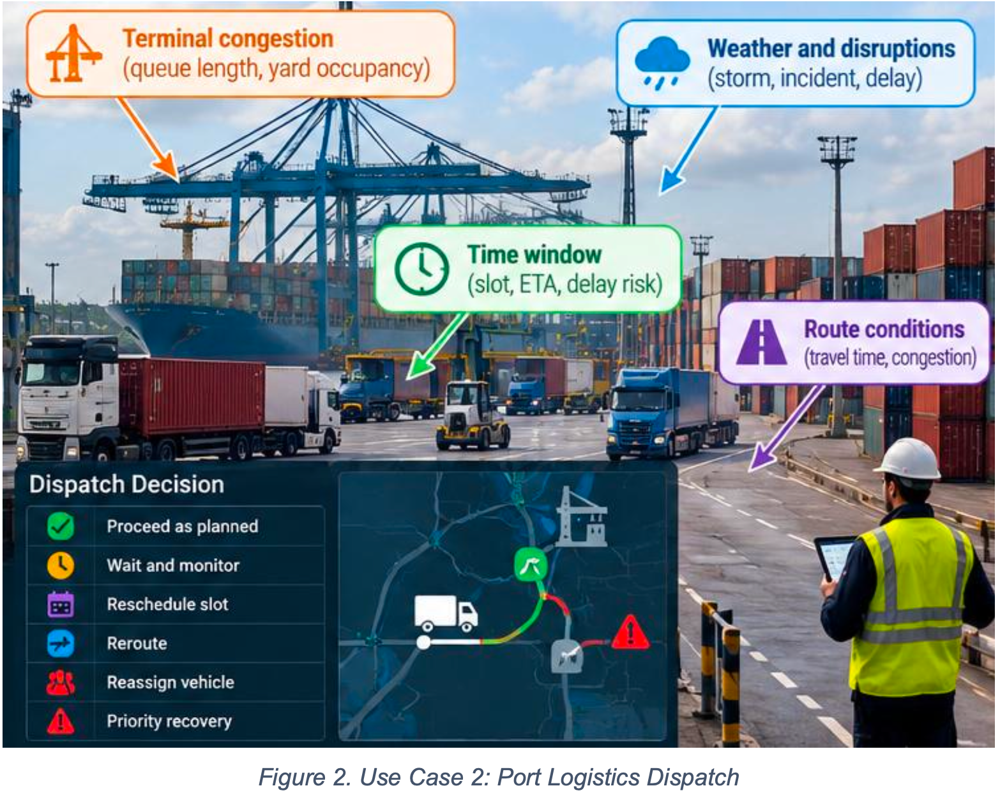

In [1]:
from pathlib import Path
from IPython.display import display, Image

BASE_DIR = Path.cwd()
DATA_PATH = Path("../MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/classification_logistics.csv")
# Search likely project-relative locations so the contextual figure works in a clone,
# while avoiding any machine-specific absolute paths.
figure_candidates = [
    BASE_DIR / "Figure_2_Port_Logistics_Dispatch_Use_Case.png",
    BASE_DIR / "images" / "Figure_2_Port_Logistics_Dispatch_Use_Case.png",
    BASE_DIR / "assets" / "Figure_2_Port_Logistics_Dispatch_Use_Case.png",
    BASE_DIR / "figures" / "Figure_2_Port_Logistics_Dispatch_Use_Case.png",
]
FIGURE_PATH = next((p for p in figure_candidates if p.exists()), None)
if FIGURE_PATH is not None:
    display(Image(filename=str(FIGURE_PATH), width=1000))
else:
    print("Contextual use-case image is not present in the repository. The analysis does not depend on it; add it under images/ or the project root if it is required for submission.")


**Figure 1.** Supplied project use-case illustration for Port Logistics Dispatch. The visual is contextual rather than an analytical result.

In [2]:
# Core imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from pandas.plotting import parallel_coordinates

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.figsize"] = (10, 6)

PLOT_DIR = BASE_DIR / "plots-2-updated"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Recommended_Dispatch_Action"
ID_COL = "Observation_ID"

def savefig(name, bbox_inches="tight"):
    path = PLOT_DIR / f"{name}.png"
    plt.savefig(path, dpi=180, bbox_inches=bbox_inches)
    print(f"Saved: {path}")

def show_and_save(name, bbox_inches="tight"):
    savefig(name, bbox_inches=bbox_inches)
    # Embed a downscaled preview from the saved figure to keep the executed notebook compact.
    path = PLOT_DIR / f"{name}.png"
    display(Image(filename=str(path), width=900))
    plt.close("all")


In [3]:
# Preserve the supplied CSV unchanged in df_raw. The assignment specifies 10,000 cases.
# Structural audit: the first 10,000 rows contain Observation_ID 1..10,000 exactly once;
# the following 250 rows are appended repeated-ID records. Use that identifiable 10,000-row
# block provisionally for EDA; do NOT choose among conflicting appended records at random.
df_raw = pd.read_csv(DATA_PATH)
EXPECTED_CASES = 10_000

def _normalise_text(series):
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

weekday_map = {
    "mon":"Mon", "monday":"Mon", "tue":"Tue", "tues":"Tue", "tuesday":"Tue",
    "wed":"Wed", "wednesday":"Wed", "thu":"Thu", "thur":"Thu", "thurs":"Thu", "thursday":"Thu",
    "fri":"Fri", "friday":"Fri", "sat":"Sat", "saturday":"Sat", "sun":"Sun", "sunday":"Sun"
}
shift_map = {"day":"Day", "evening":"Evening", "night":"Night"}
vehicle_map = {
    "tractor_unit":"Tractor_Unit", "tractor-unit":"Tractor_Unit", "tractor unit":"Tractor_Unit",
    "swap_body_truck":"Swap_Body_Truck", "swap-body-truck":"Swap_Body_Truck", "swap body truck":"Swap_Body_Truck",
    "rigid_truck":"Rigid_Truck", "rigid-truck":"Rigid_Truck", "rigid truck":"Rigid_Truck",
}

def standardize_categories(frame):
    out = frame.copy(deep=True)
    if "Day_of_Week" in out:
        out["Day_of_Week"] = _normalise_text(out["Day_of_Week"]).str.lower().map(weekday_map).astype("string")
    if "Shift" in out:
        out["Shift"] = _normalise_text(out["Shift"]).str.lower().map(shift_map).astype("string")
    if "Vehicle_Type" in out:
        out["Vehicle_Type"] = _normalise_text(out["Vehicle_Type"]).str.lower().map(vehicle_map).astype("string")
    for col in out.select_dtypes(include=["object", "string"]).columns:
        if col not in {"Day_of_Week", "Shift", "Vehicle_Type"}:
            out[col] = _normalise_text(out[col]).replace("", pd.NA)
    return out

# Full standardized copy is only for comparing raw-vs-standardized duplicate counts.
df_standardized_all = standardize_categories(df_raw)

# Verify the assignment-sized block structurally rather than deleting arbitrary rows.
first_block = df_raw.iloc[:EXPECTED_CASES].copy(deep=True)
expected_ids = pd.Series(np.arange(1, EXPECTED_CASES + 1), name=ID_COL)
first_block_ids_match = (
    len(first_block) == EXPECTED_CASES
    and first_block[ID_COL].reset_index(drop=True).equals(expected_ids)
)
df_clean = standardize_categories(first_block)
df = df_clean  # All downstream EDA uses this corrected 10,000-case analysis copy.

print(f"Raw file shape: {df_raw.shape}")
print(f"First-block Observation_ID sequence is exactly 1..{EXPECTED_CASES}: {first_block_ids_match}")
print(f"Provisional analysis shape: {df.shape}")
print(f"Unique IDs in analysis copy: {df[ID_COL].nunique(dropna=True):,}")
print("Decision: use rows 1–10,000 provisionally because they form the ordered unique-ID block.")
print("The 250 appended records are audited below; 54 conflicting records remain for instructor confirmation.")
display(df.head())


Raw file shape: (10250, 41)
First-block Observation_ID sequence is exactly 1..10000: True
Provisional analysis shape: (10000, 41)
Unique IDs in analysis copy: 10,000
Decision: use rows 1–10,000 provisionally because they form the ordered unique-ID block.
The 250 appended records are audited below; 54 conflicting records remain for instructor confirmation.


,Observation_ID,Event_Timestamp,Day_of_Week,Shift,Terminal_ID,Corridor_ID,Transport_Object_Type,Vehicle_Type,Distance_to_Terminal_km,Weather_Severity_Index,...,Alternative_Terminal_Available,Alternative_Route_Available,Alternative_Route_Extra_km,Nearby_Compatible_Vehicles,Driver_Change_Available,Historical_Route_Reliability_pct,Disruptions_Last_7d,Data_Quality_Score_pct,Estimated_CO2_kg,Recommended_Dispatch_Action
0,1,2027-04-29 06:20:00,Thu,Day,T1,C1,Container,Tractor_Unit,92.88,8.64,...,False,True,3.99,1.0,False,88.36,5.0,96.20,90.02,PRIORITY_RECOVERY
1,2,2027-06-27 14:36:00,Sun,Evening,T1,C4,Trailer,Tractor_Unit,88.66,26.61,...,False,False,NaN,0.0,False,89.85,5.0,94.98,68.10,PROCEED_AS_PLANNED
2,3,2026-12-02 22:51:00,Wed,Night,T4,C3,Trailer,Tractor_Unit,30.60,19.01,...,False,True,35.86,4.0,True,90.22,3.0,98.44,20.00,PROCEED_AS_PLANNED
3,4,2026-12-30 17:45:00,Wed,Evening,T2,C1,Container,Tractor_Unit,97.52,8.60,...,False,True,27.85,2.0,False,89.08,6.0,98.77,61.87,REASSIGN_VEHICLE
4,5,2027-02-01 00:14:00,Mon,Night,T3,C3,Swap_Body,Rigid_Truck,129.40,13.18,...,False,True,10.68,3.0,True,89.24,4.0,97.78,104.38,REASSIGN_VEHICLE


## 2. Dataset description and data dictionary

The assignment specifies **10,000 dispatch cases**. The supplied CSV contains 10,250 rows, but its first 10,000 rows form an ordered block with unique `Observation_ID` values 1–10,000. The final 250 rows are appended repeated-ID records. To avoid reporting the extra records as separate cases, the EDA uses the first 10,000 rows as a **provisional canonical analysis copy**, with the conflicting appended records audited in Section 11A and awaiting instructor/data-owner confirmation. The raw file remains unchanged.

The feature groups are interpreted according to the project brief:

- **Temporal/context:** timestamp, day, shift, terminal, corridor
- **Transport:** object and vehicle type, distance
- **Disruption:** weather, terminal/road incidents, congestion, delay, ETA uncertainty
- **Terminal handling:** yard occupancy, queue, gate processing
- **Slot:** window length and buffer
- **Operational readiness:** trailer, customs, vehicle technical status
- **Resource constraints:** driver hours, compatible vehicles, driver change
- **Alternatives:** alternative slot/terminal/route and route extra distance
- **Commercial/sustainability:** service-level penalty, CO₂
- **Target:** recommended dispatch action

All downstream tables and figures are generated from `df`, the standardized 10,000-row analysis copy.


In [4]:
# Final analysis-dataset validation (all downstream EDA must use df, not df_raw).
n_rows, n_cols = df.shape
repeated_id_count = int(df[ID_COL].duplicated().sum())
exact_duplicate_count = int(df.duplicated().sum())
print(f"Raw supplied rows: {len(df_raw):,}")
print(f"Raw unique Observation_IDs: {df_raw[ID_COL].nunique(dropna=True):,}")
print(f"Final provisional analysis rows: {n_rows:,}")
print(f"Final unique Observation_IDs: {df[ID_COL].nunique(dropna=True):,}")
print(f"Exact duplicate rows remaining in analysis: {exact_duplicate_count:,}")
print(f"Repeated Observation_ID occurrences remaining in analysis: {repeated_id_count:,}")
print(f"Columns: {n_cols:,}")
assert n_rows == EXPECTED_CASES, f"Expected {EXPECTED_CASES} analysis rows, found {n_rows}"
assert df[ID_COL].nunique(dropna=True) == EXPECTED_CASES
assert exact_duplicate_count == 0
assert repeated_id_count == 0


Raw supplied rows: 10,250
Raw unique Observation_IDs: 10,000
Final provisional analysis rows: 10,000
Final unique Observation_IDs: 10,000
Exact duplicate rows remaining in analysis: 0
Repeated Observation_ID occurrences remaining in analysis: 0
Columns: 41


In [5]:
# Data types
dtype_table = pd.DataFrame({
    "feature": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "missing_pct": (df.isna().mean() * 100).round(2).values,
    "unique_values": df.nunique(dropna=True).values
})
display(dtype_table)


,feature,dtype,non_null,missing,missing_pct,unique_values
0,Observation_ID,int64,10000,0,0.00,10000
1,Event_Timestamp,string,10000,0,0.00,9906
2,Day_of_Week,string,9900,100,1.00,7
3,Shift,string,9900,100,1.00,3
4,Terminal_ID,string,9900,100,1.00,4
5,Corridor_ID,string,9900,100,1.00,5
6,Transport_Object_Type,string,9900,100,1.00,3
7,Vehicle_Type,string,9900,100,1.00,3
8,Distance_to_Terminal_km,float64,9900,100,1.00,6788
9,Weather_Severity_Index,float64,9900,100,1.00,3884


In [6]:
# Numeric statistical profile
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_summary = df[numeric_cols].describe().T
numeric_summary["missing"] = df[numeric_cols].isna().sum()
numeric_summary["missing_pct"] = df[numeric_cols].isna().mean() * 100
display(numeric_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
Observation_ID,10000.0,5000.500,2886.896,1.00,2500.750,5000.500,7500.250,10000.00,0,0.00
Distance_to_Terminal_km,9900.0,73.204,74.923,5.00,35.440,54.890,86.197,842.05,100,1.00
Weather_Severity_Index,9900.0,17.177,13.901,0.02,6.938,13.360,23.582,98.01,100,1.00
Terminal_Incident_Severity,9900.0,0.208,0.567,0.00,0.000,0.000,0.000,3.00,100,1.00
Road_Incident_Severity,9900.0,0.177,0.520,0.00,0.000,0.000,0.000,3.00,100,1.00
Terminal_Congestion_Index,9900.0,49.327,16.222,0.00,37.908,47.935,60.022,100.00,100,1.00
Road_Congestion_Index,9900.0,47.979,19.506,0.00,33.608,45.210,61.222,100.00,100,1.00
Yard_Occupancy_pct,9543.0,67.135,10.621,32.11,59.950,66.880,74.340,100.00,457,4.57
Queue_Length_vehicles,9700.0,9.460,4.228,0.00,7.000,9.000,12.000,29.00,300,3.00
Gate_Processing_Time_min,9750.0,22.467,12.096,5.00,16.530,20.730,25.670,151.38,250,2.50


In [7]:
# Categorical/boolean profile
categorical_cols = df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

cat_profile = []
for col in categorical_cols:
    vc = df[col].value_counts(dropna=False)
    top_value = vc.index[0] if len(vc) else np.nan
    cat_profile.append({
        "feature": col,
        "dtype": str(df[col].dtype),
        "unique_non_null": df[col].nunique(dropna=True),
        "missing": df[col].isna().sum(),
        "missing_pct": df[col].isna().mean() * 100,
        "most_common": top_value,
        "most_common_count": vc.iloc[0] if len(vc) else 0,
        "most_common_pct": vc.iloc[0] / len(df) * 100 if len(vc) else 0
    })
display(pd.DataFrame(cat_profile).round(3))


,feature,dtype,unique_non_null,missing,missing_pct,most_common,most_common_count,most_common_pct
0,Trailer_Ready,bool,2,0,0.0,True,9299,92.99
1,Alternative_Slot_Available,bool,2,0,0.0,True,5437,54.37
2,Alternative_Terminal_Available,bool,2,0,0.0,False,5781,57.81
3,Alternative_Route_Available,bool,2,0,0.0,True,7828,78.28
4,Driver_Change_Available,bool,2,0,0.0,False,5619,56.19


## 3. Missing-value analysis

Missingness is recalculated on the corrected 10,000-row analysis copy after category standardization. Missing values are not automatically imputed during EDA. `Alternative_Route_Extra_km` is checked against `Alternative_Route_Available`: if missing distances correspond to unavailable routes, those blanks mean “not applicable” rather than zero. The audit lists any exceptions. The route-distance comparison and missing-value percentages are based on the final analysis denominator of 10,000 cases.


,missing_count,missing_pct
Alternative_Route_Extra_km,2172,21.72
ETA_Uncertainty_min,569,5.69
Yard_Occupancy_pct,457,4.57
Expected_Disruption_Duration_min,400,4.00
Queue_Length_vehicles,300,3.00
Current_Delay_min,300,3.00
Gate_Processing_Time_min,250,2.50
Historical_Route_Reliability_pct,202,2.02
Terminal_ID,100,1.00
Estimated_CO2_kg,100,1.00


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/01_missing_value_rate.png


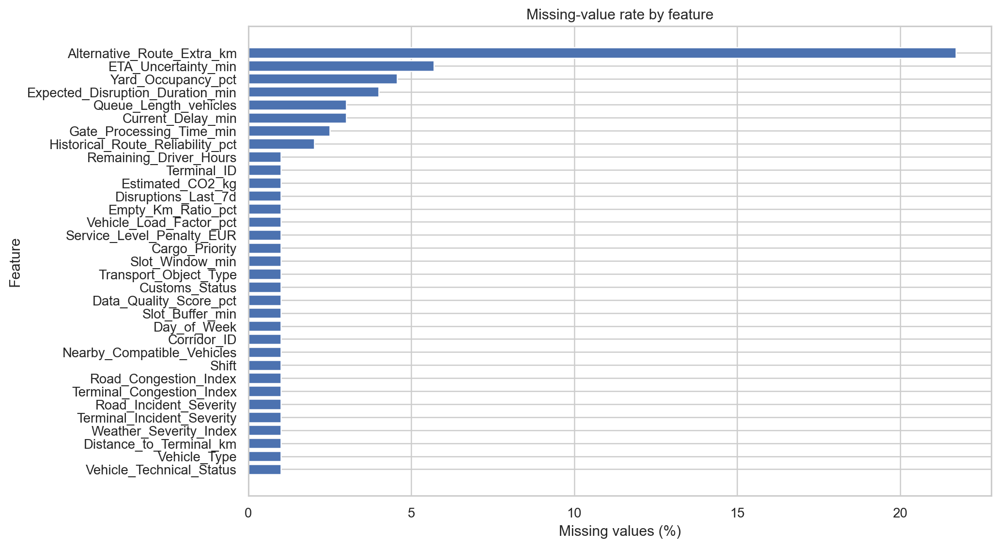

In [8]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
})
display(missing_table[missing_table["missing_count"] > 0])

plt.figure(figsize=(11, 7))
m = missing_table[missing_table["missing_count"] > 0].sort_values("missing_pct")
plt.barh(m.index.astype(str), m["missing_pct"].values)
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Missing-value rate by feature")
show_and_save("01_missing_value_rate")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/02_missingness_pattern.png


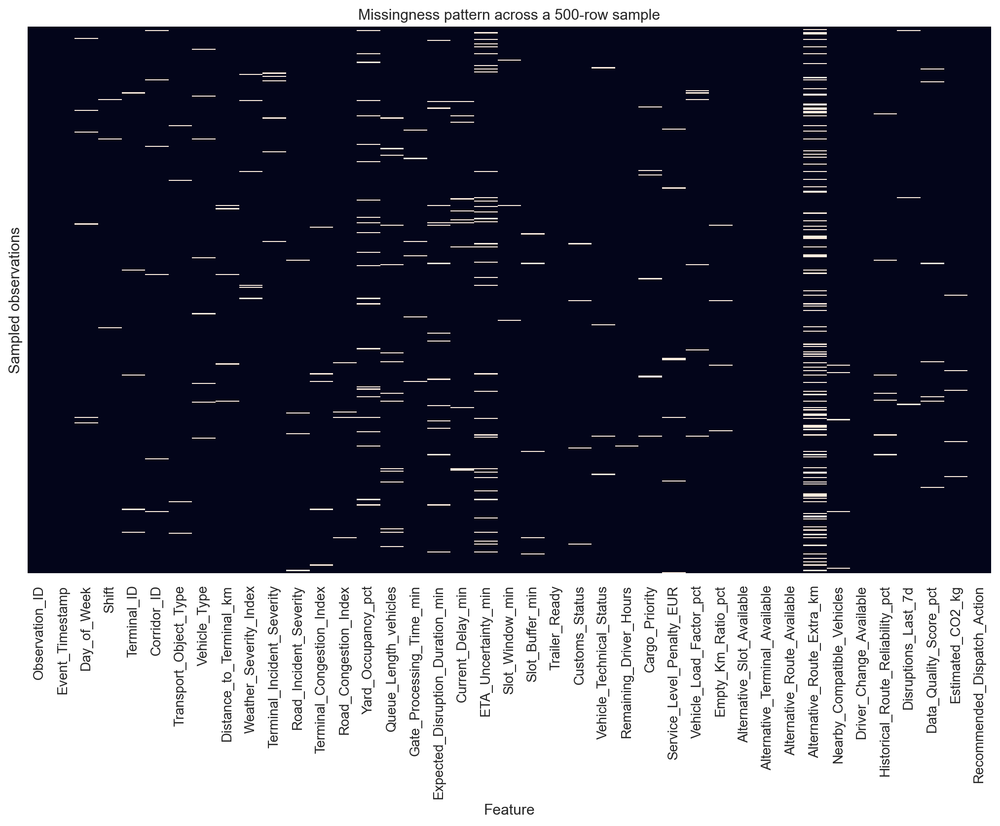

In [9]:
# Missingness pattern heatmap for a compact sample of rows
sample_for_missing = df.sample(min(500, len(df)), random_state=42)
plt.figure(figsize=(14, 8))
sns.heatmap(sample_for_missing.isna(), cbar=False, yticklabels=False)
plt.xlabel("Feature")
plt.ylabel("Sampled observations")
plt.title("Missingness pattern across a 500-row sample")
show_and_save("02_missingness_pattern")


## 4. Target variable: recommended dispatch action

The target has six operational classes. Class frequencies are examined before relationship analysis because class imbalance can affect how patterns are interpreted in later classification work.

,count,percentage
Recommended_Dispatch_Action,,
PROCEED_AS_PLANNED,2219,22.19
WAIT_AND_MONITOR,2128,21.28
PRIORITY_RECOVERY,1571,15.71
RESCHEDULE_SLOT,1497,14.97
REROUTE,1334,13.34
REASSIGN_VEHICLE,1251,12.51


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/03_target_class_distribution.png


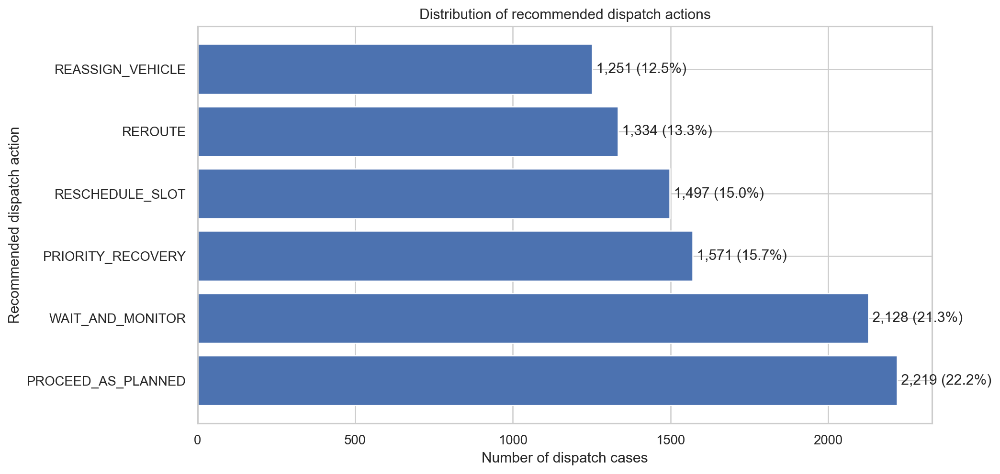

In [10]:
target_counts = df[TARGET].value_counts(dropna=False)
target_pct = target_counts / len(df) * 100
target_table = pd.DataFrame({"count": target_counts, "percentage": target_pct.round(2)})
display(target_table)

plt.figure(figsize=(11, 6))
order = target_counts.index.tolist()
plt.barh(order, target_counts.values)
plt.xlabel("Number of dispatch cases")
plt.ylabel("Recommended dispatch action")
plt.title("Distribution of recommended dispatch actions")
for i, v in enumerate(target_counts.values):
    plt.text(v, i, f" {v:,} ({v/len(df)*100:.1f}%)", va="center")
show_and_save("03_target_class_distribution")


,count,percent
Recommended_Dispatch_Action,,
PROCEED_AS_PLANNED,2219,22.19
WAIT_AND_MONITOR,2128,21.28
PRIORITY_RECOVERY,1571,15.71
RESCHEDULE_SLOT,1497,14.97
REROUTE,1334,13.34
REASSIGN_VEHICLE,1251,12.51


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/04_target_class_distribution.png


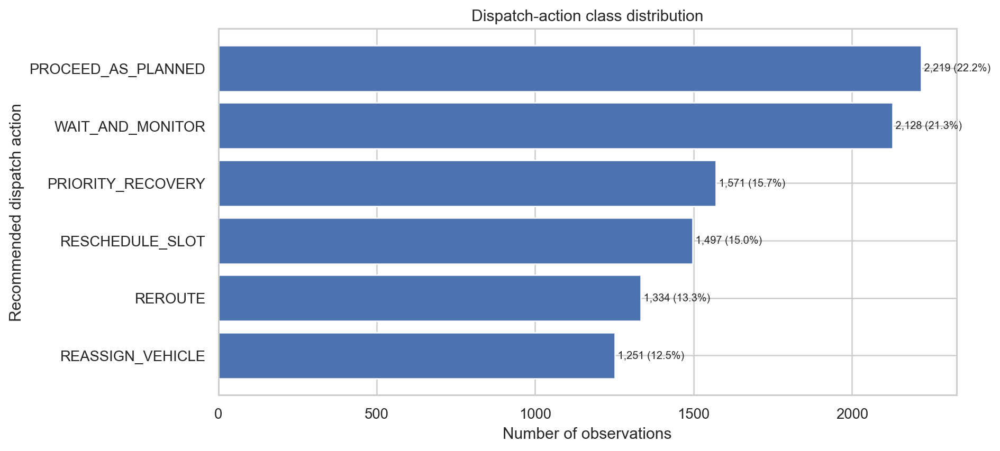

In [11]:
target_counts = df[TARGET].value_counts(dropna=False).sort_values(ascending=True)
target_pct = target_counts / len(df) * 100
target_table = pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)})
display(target_table.sort_values("count", ascending=False))

plt.figure(figsize=(10, 5))
plt.barh(target_counts.index.astype(str), target_counts.values)
plt.xlabel("Number of observations")
plt.ylabel("Recommended dispatch action")
plt.title("Dispatch-action class distribution")
for y, value in enumerate(target_counts.values):
    plt.text(value, y, f" {value:,} ({value / len(df):.1%})", va="center", fontsize=8)
show_and_save("04_target_class_distribution")


## 5. Categorical-variable analysis

The rubric specifically requests categorical analysis using bar charts and histograms. The following plots examine the major operational categorical variables and their class composition.

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_day_of_week.png


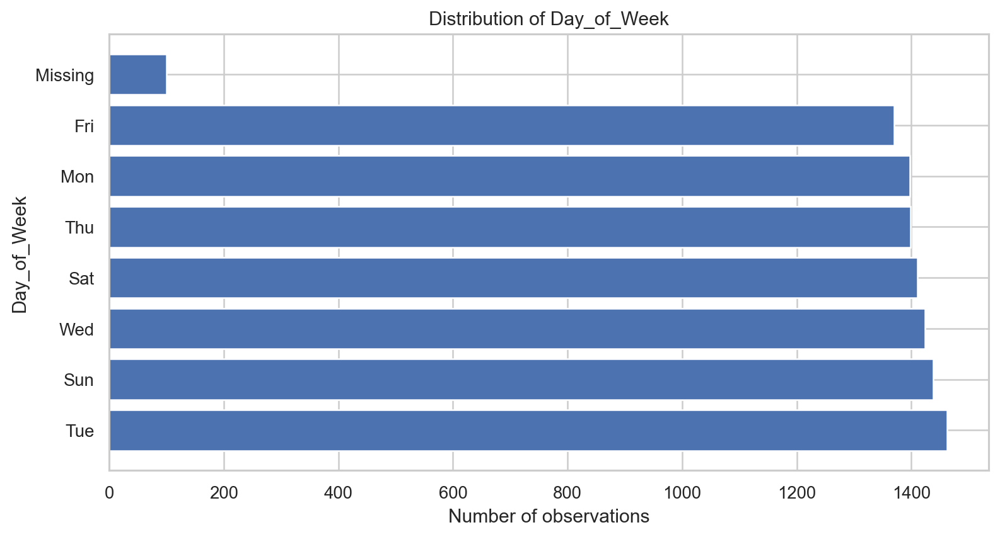

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_shift.png


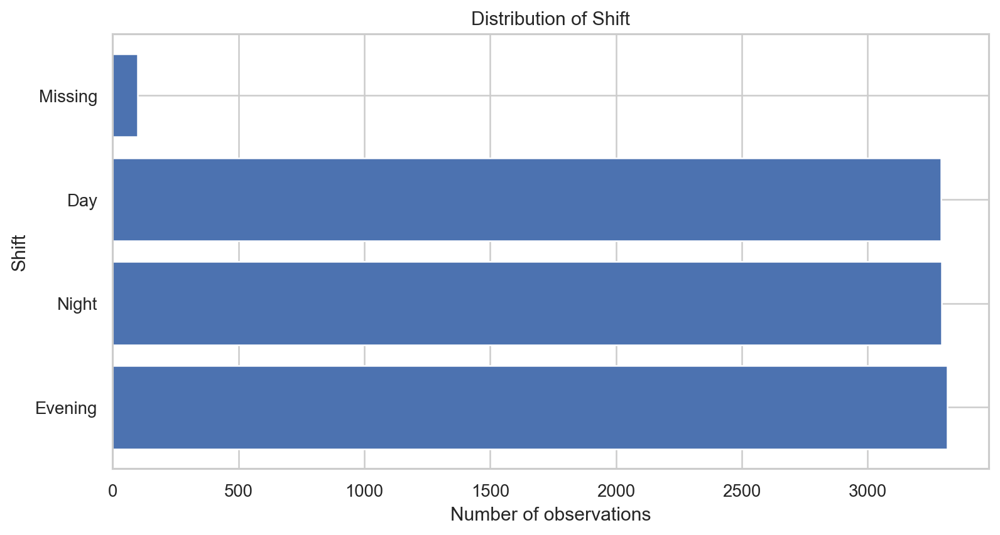

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_terminal_id.png


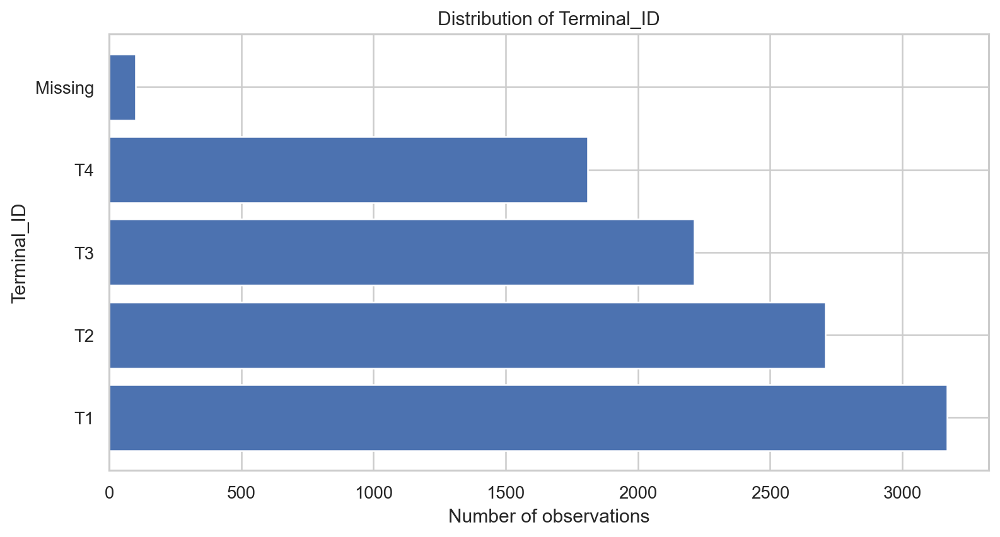

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_corridor_id.png


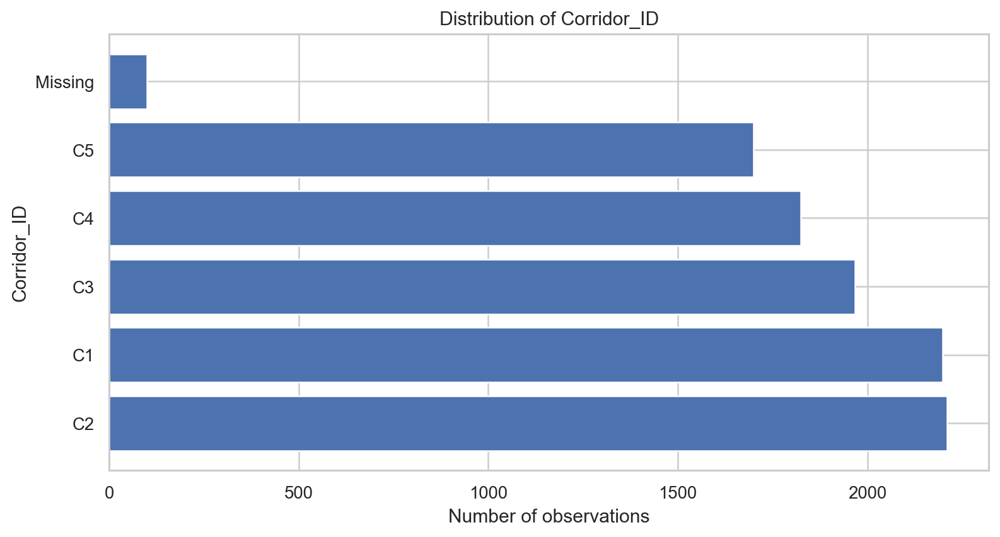

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_transport_object_type.png


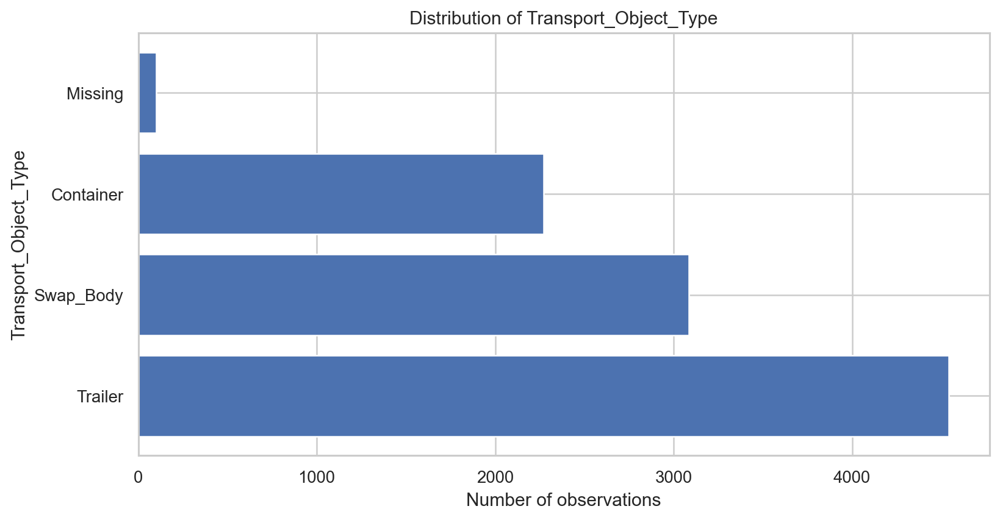

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_vehicle_type.png


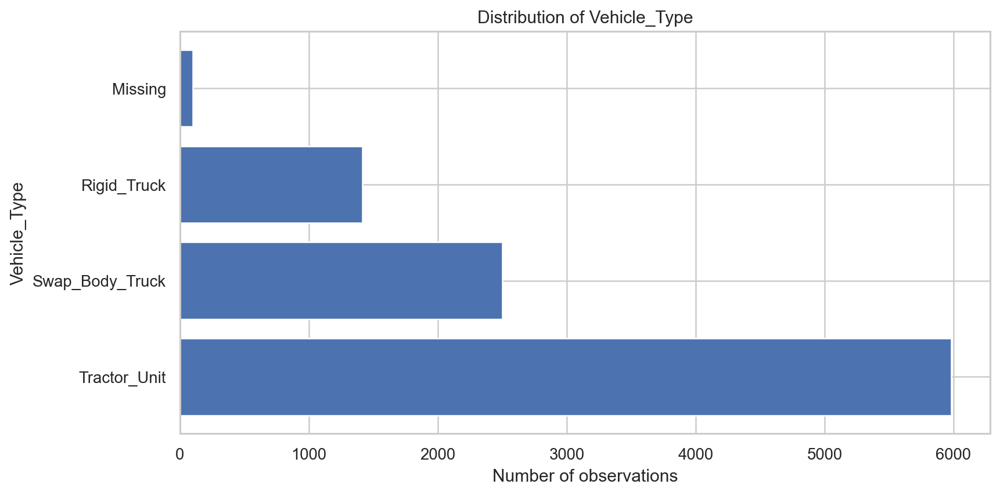

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_customs_status.png


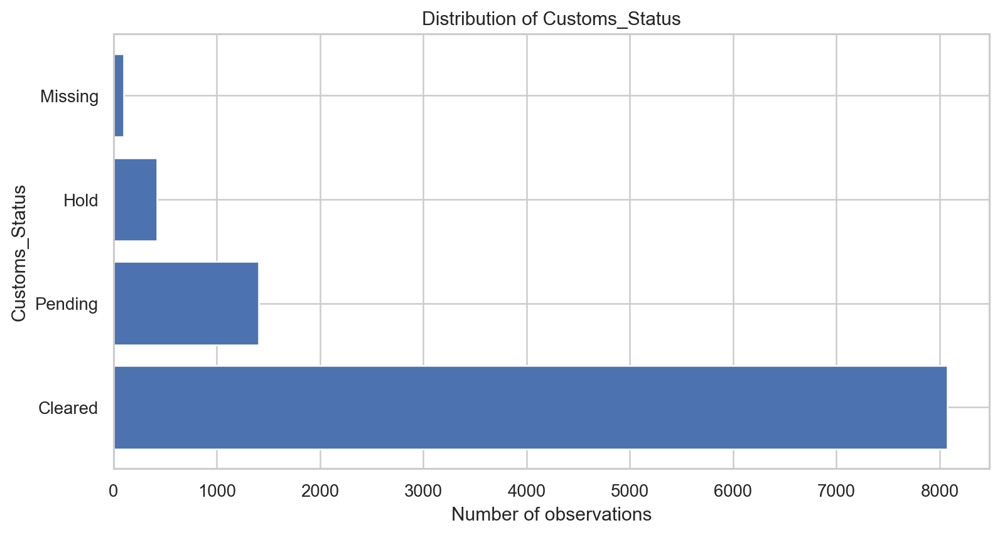

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/05_categorical_vehicle_technical_status.png


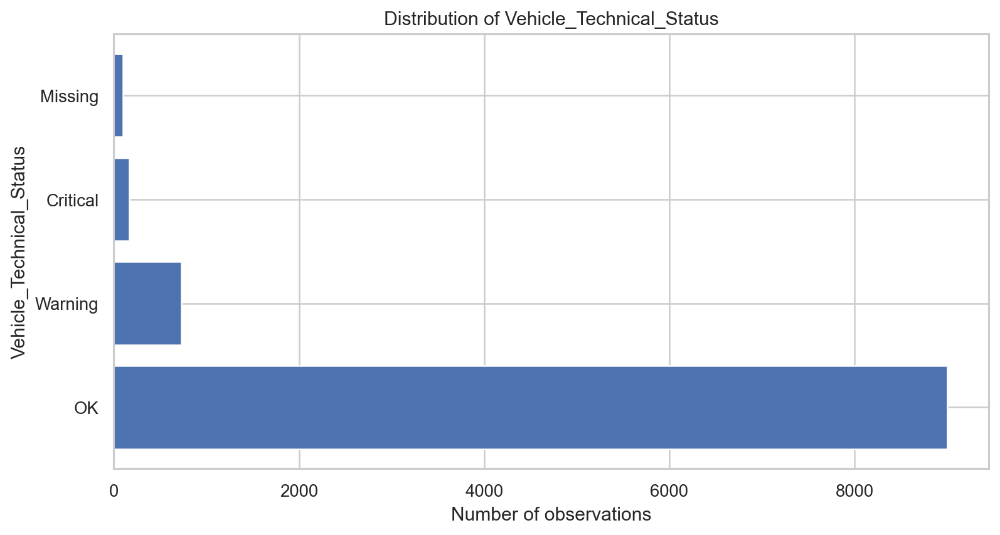

In [12]:
cat_plot_cols = ['Day_of_Week', 'Shift', 'Terminal_ID', 'Corridor_ID', 'Transport_Object_Type', 'Vehicle_Type', 'Customs_Status', 'Vehicle_Technical_Status']

for col in cat_plot_cols:
    counts = df[col].fillna("Missing").value_counts()
    plt.figure(figsize=(10, 5))
    plt.barh(counts.index.astype(str), counts.values)
    plt.xlabel("Number of observations")
    plt.ylabel(col)
    plt.title(f"Distribution of {col}")
    show_and_save(f"05_categorical_{col.lower()}")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/06_boolean_operational_variables.png


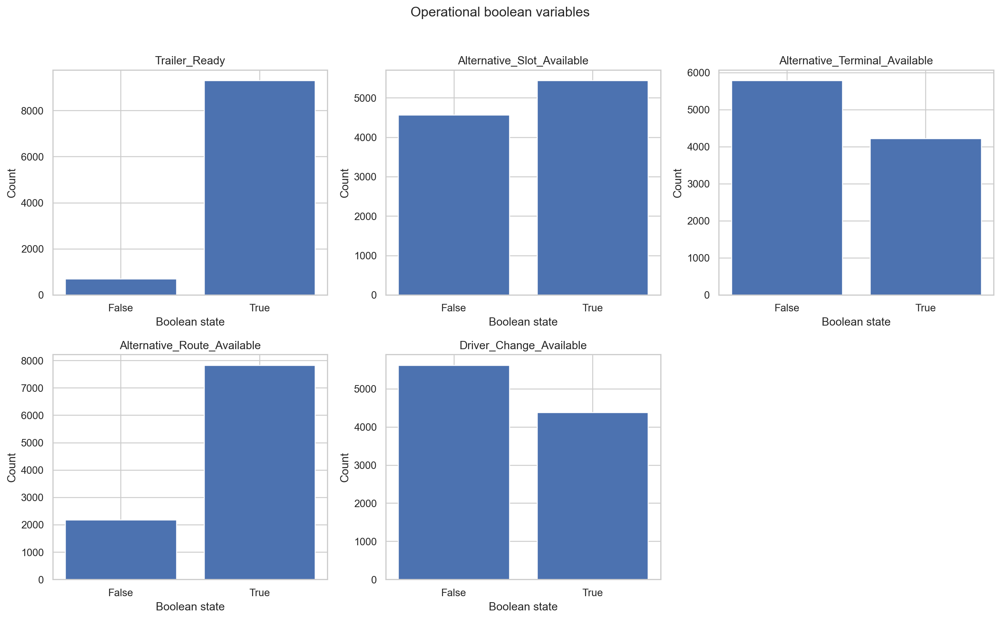

In [13]:
# Boolean operational readiness / alternatives
bool_cols = ["Trailer_Ready", "Alternative_Slot_Available", "Alternative_Terminal_Available",
             "Alternative_Route_Available", "Driver_Change_Available"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for ax, col in zip(axes, bool_cols):
    counts = df[col].fillna(False).value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(col)
    ax.set_xlabel("Boolean state")
    ax.set_ylabel("Count")
for ax in axes[len(bool_cols):]:
    ax.axis("off")
plt.suptitle("Operational boolean variables", y=1.02)
plt.tight_layout()
show_and_save("06_boolean_operational_variables")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/07_target_composition_by_terminal_id.png


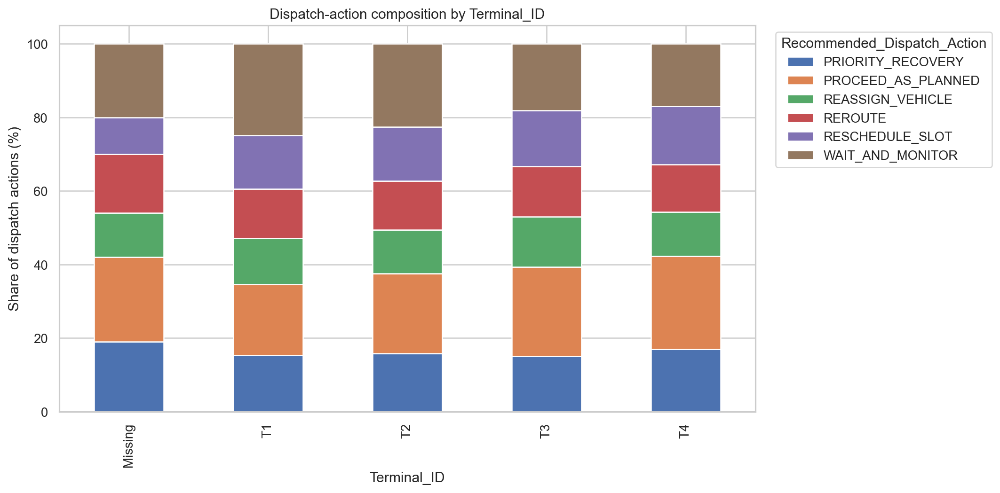

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/07_target_composition_by_corridor_id.png


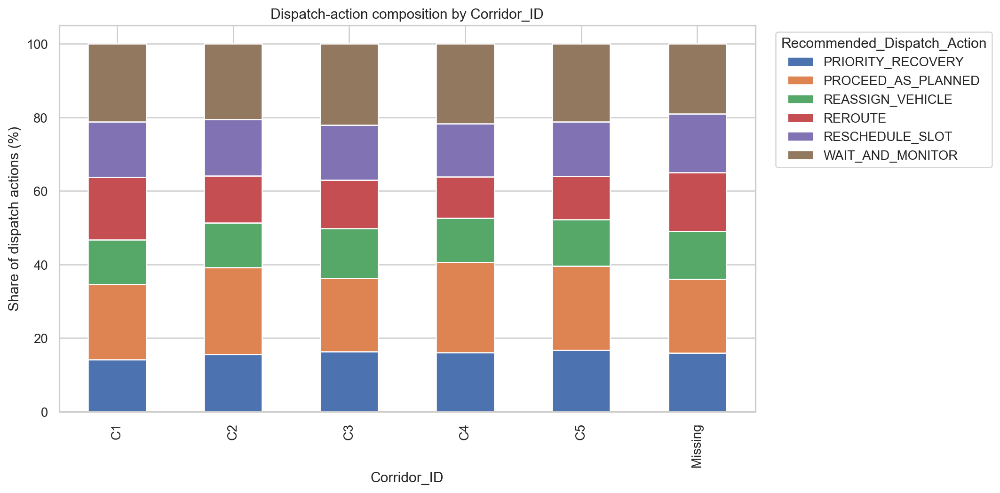

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/07_target_composition_by_shift.png


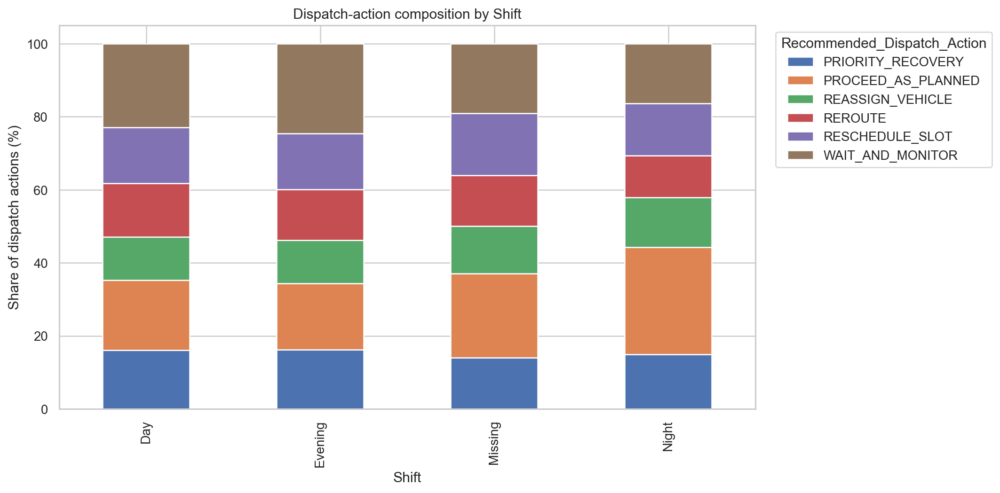

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/07_target_composition_by_transport_object_type.png


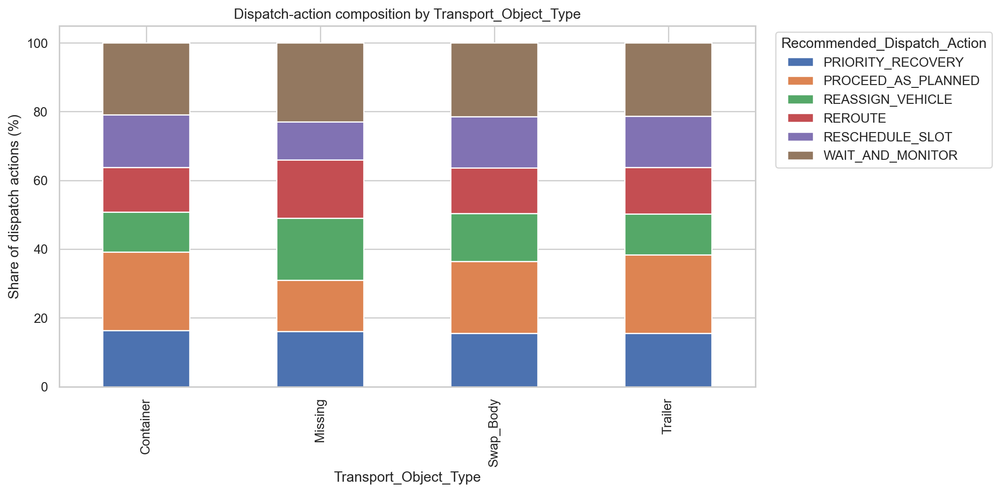

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/07_target_composition_by_vehicle_technical_status.png


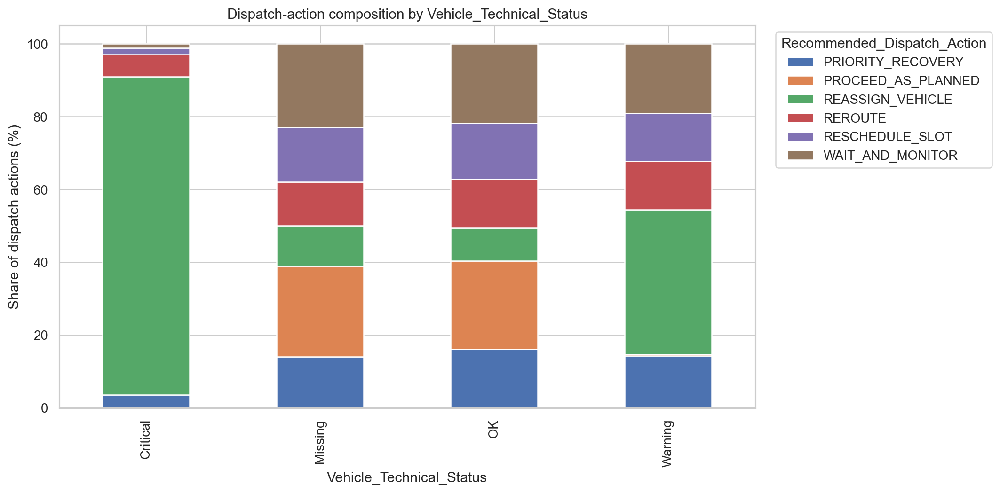

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/07_target_composition_by_customs_status.png


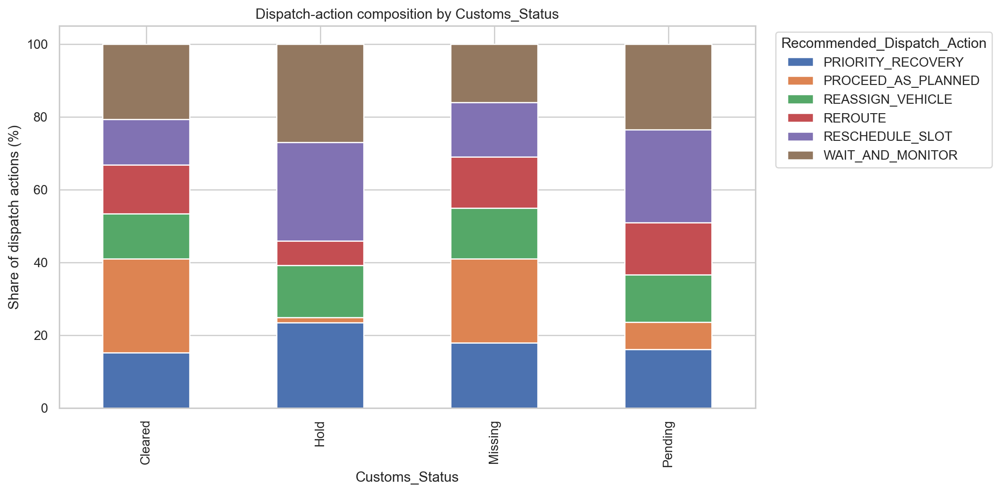

In [14]:
# Target composition by major categorical variables
for col in ["Terminal_ID", "Corridor_ID", "Shift", "Transport_Object_Type", "Vehicle_Technical_Status", "Customs_Status"]:
    ct = pd.crosstab(df[col].fillna("Missing"), df[TARGET], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, figsize=(12, 6))
    plt.ylabel("Share of dispatch actions (%)")
    plt.xlabel(col)
    plt.title(f"Dispatch-action composition by {col}")
    plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    show_and_save(f"07_target_composition_by_{col.lower()}")


## 6. Numerical-variable analysis

The project rubric requires histograms/KDE, box plots, and violin plots. The analysis below uses the numerical operational variables rather than identifiers. Variables are grouped into readable panels so the plots remain interpretable.

In [15]:
# Numeric features used for distribution, outlier, and relationship analysis
numeric_features = [c for c in numeric_cols if c != ID_COL]
print(f"Numeric operational features analysed: {len(numeric_features)}")


Numeric operational features analysed: 25


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/08_numerical_histograms_kde.png


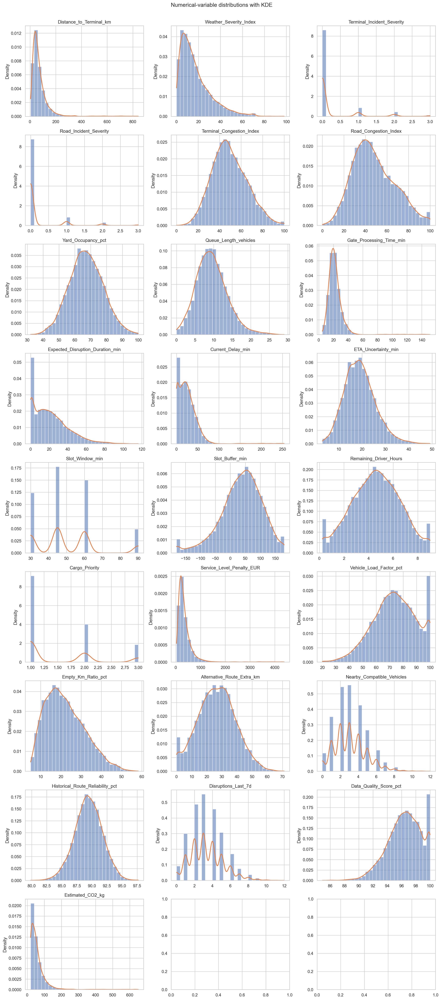

In [16]:
# Histograms + KDE (matplotlib + scipy for compatibility)
ncols = 3
nrows = int(np.ceil(len(numeric_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_features):
    values = df[col].dropna().to_numpy()
    ax.hist(values, bins=30, density=True, alpha=0.55)
    if len(values) > 1 and np.std(values) > 0:
        kde = stats.gaussian_kde(values)
        x_grid = np.linspace(values.min(), values.max(), 300)
        ax.plot(x_grid, kde(x_grid), linewidth=2)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Density")
fig.suptitle("Numerical-variable distributions with KDE", y=1.002)
plt.tight_layout()
show_and_save("08_numerical_histograms_kde")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/09_numerical_boxplots.png


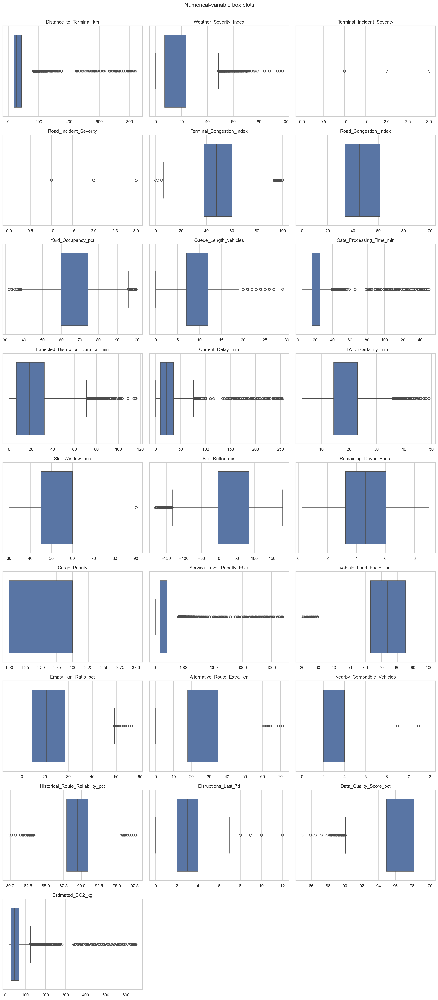

In [17]:
# Box plots
ncols = 3
nrows = int(np.ceil(len(numeric_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_features):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes[len(numeric_features):]:
    ax.axis("off")
fig.suptitle("Numerical-variable box plots", y=1.002)
plt.tight_layout()
show_and_save("09_numerical_boxplots")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/10_selected_violin_plots_by_target.png


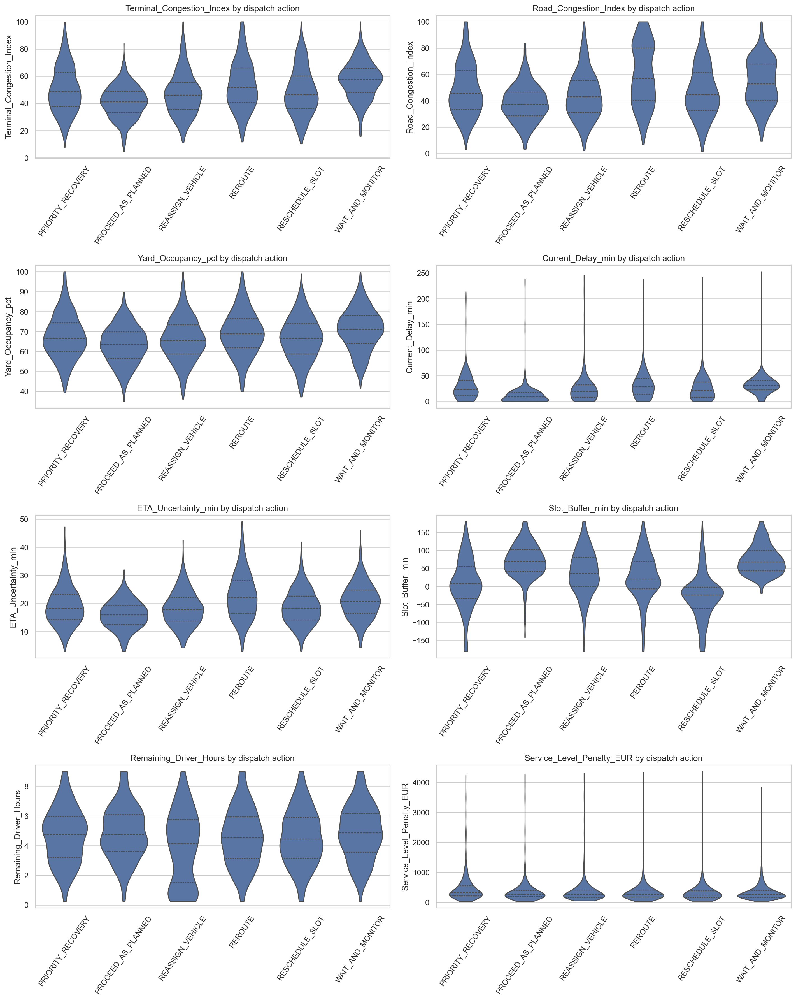

In [18]:
# Violin plots against the six-class target. Use a stratified display sample per class
# to keep KDE rendering responsive; numeric summaries and all other analyses use all 10,000 rows.
violin_features = [
    "Terminal_Congestion_Index", "Road_Congestion_Index", "Yard_Occupancy_pct",
    "Current_Delay_min", "ETA_Uncertainty_min", "Slot_Buffer_min",
    "Remaining_Driver_Hours", "Service_Level_Penalty_EUR"
]
violin_parts = []
for action, group in df.groupby(TARGET, dropna=False):
    violin_parts.append(group.sample(n=min(len(group), 700), random_state=42))
violin_plot_data = pd.concat(violin_parts, ignore_index=True)

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for ax, col in zip(axes.ravel(), violin_features):
    sns.violinplot(data=violin_plot_data, x=TARGET, y=col, ax=ax, inner="quartile", cut=0)
    ax.set_title(col + " by dispatch action")
    ax.tick_params(axis="x", rotation=55)
    ax.set_xlabel("")
for ax in axes.ravel()[len(violin_features):]:
    ax.axis("off")
plt.tight_layout()
show_and_save("10_selected_violin_plots_by_target")


## 7. Outlier detection

Potential outliers are identified with the 1.5×IQR rule as a screening method. They are **not automatically removed**. NIST notes that unusual observations may represent errors, random variation, or scientifically/operationally meaningful cases, so they should be investigated before deletion.

This distinction is important in a dispatch dataset: extreme delay, congestion, or disruption values may be precisely the situations in which exceptional dispatch actions occur.

,feature,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct
2,Terminal_Incident_Severity,0.000,0.000,0.000,0.000,0.000,1393,13.93
3,Road_Incident_Severity,0.000,0.000,0.000,0.000,0.000,1234,12.34
12,Slot_Window_min,45.000,60.000,15.000,22.500,82.500,968,9.68
0,Distance_to_Terminal_km,35.440,86.197,50.757,-40.696,162.334,583,5.83
16,Service_Level_Penalty_EUR,179.230,425.903,246.672,-190.779,795.911,576,5.76
24,Estimated_CO2_kg,29.377,68.072,38.695,-28.665,126.115,560,5.60
1,Weather_Severity_Index,6.938,23.582,16.645,-18.030,48.550,389,3.89
8,Gate_Processing_Time_min,16.530,25.670,9.140,2.820,39.380,319,3.19
13,Slot_Buffer_min,-2.710,83.955,86.665,-132.708,213.952,238,2.38
22,Disruptions_Last_7d,2.000,4.000,2.000,-1.000,7.000,228,2.28


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/11_iqr_outlier_rates.png


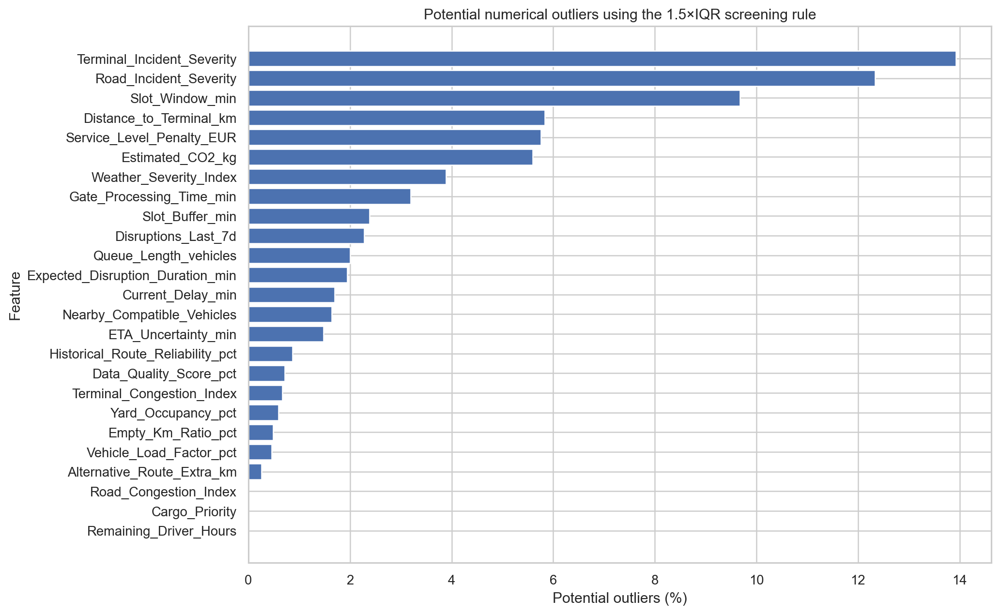

In [19]:
outlier_rows = []
for col in numeric_features:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": mask.mean() * 100
    })

outlier_table = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)
display(outlier_table.round(3))

plt.figure(figsize=(11, 8))
plot_out = outlier_table.sort_values("outlier_pct")
plt.barh(plot_out["feature"].astype(str), plot_out["outlier_pct"].values)
plt.xlabel("Potential outliers (%)")
plt.ylabel("Feature")
plt.title("Potential numerical outliers using the 1.5×IQR screening rule")
show_and_save("11_iqr_outlier_rates")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/12_outliers_by_dispatch_action.png


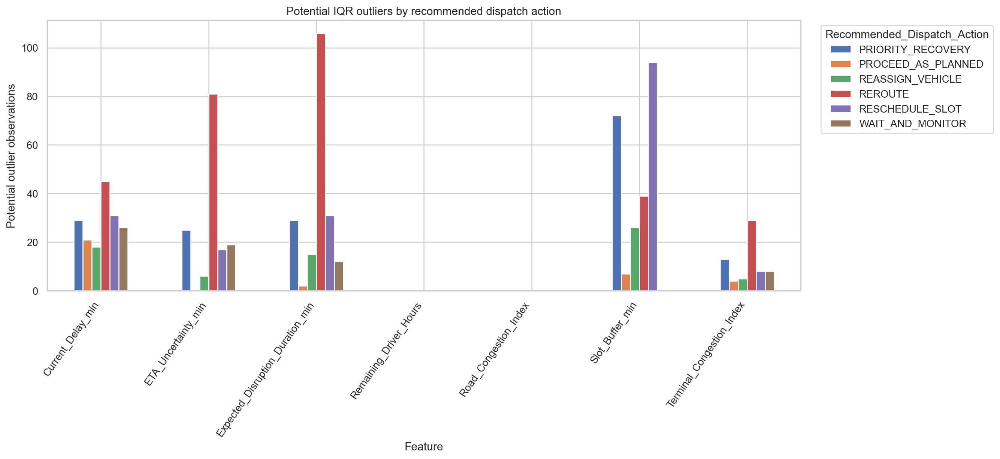

In [20]:
# Outlier count by dispatch action for key operational variables
key_outlier_features = [
    "Terminal_Congestion_Index", "Road_Congestion_Index", "Current_Delay_min",
    "ETA_Uncertainty_min", "Slot_Buffer_min", "Remaining_Driver_Hours",
    "Expected_Disruption_Duration_min"
]

records = []
for col in key_outlier_features:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    tmp = df.loc[mask, TARGET].value_counts()
    for cls in target_counts.index:
        records.append({"feature": col, "action": cls, "count": int(tmp.get(cls, 0))})

outlier_by_target = pd.DataFrame(records)
pivot = outlier_by_target.pivot(index="feature", columns="action", values="count")
pivot.plot(kind="bar", figsize=(15, 7))
plt.xlabel("Feature")
plt.ylabel("Potential outlier observations")
plt.title("Potential IQR outliers by recommended dispatch action")
plt.xticks(rotation=55, ha="right")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("12_outliers_by_dispatch_action")


## 8. Relationships among variables

The rubric explicitly requests relationship analysis. The following sections examine:

- Pearson correlation among numeric operational variables
- A scatter/pair plot using a representative subset
- Parallel coordinates for selected operational dimensions
- A bubble chart linking congestion, delay, and service-level exposure
- Target-related binned rates for variables that are operationally meaningful

Correlation is treated as a descriptive association, not proof of causality.

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/13_correlation_heatmap_annotated_lower_triangle.png


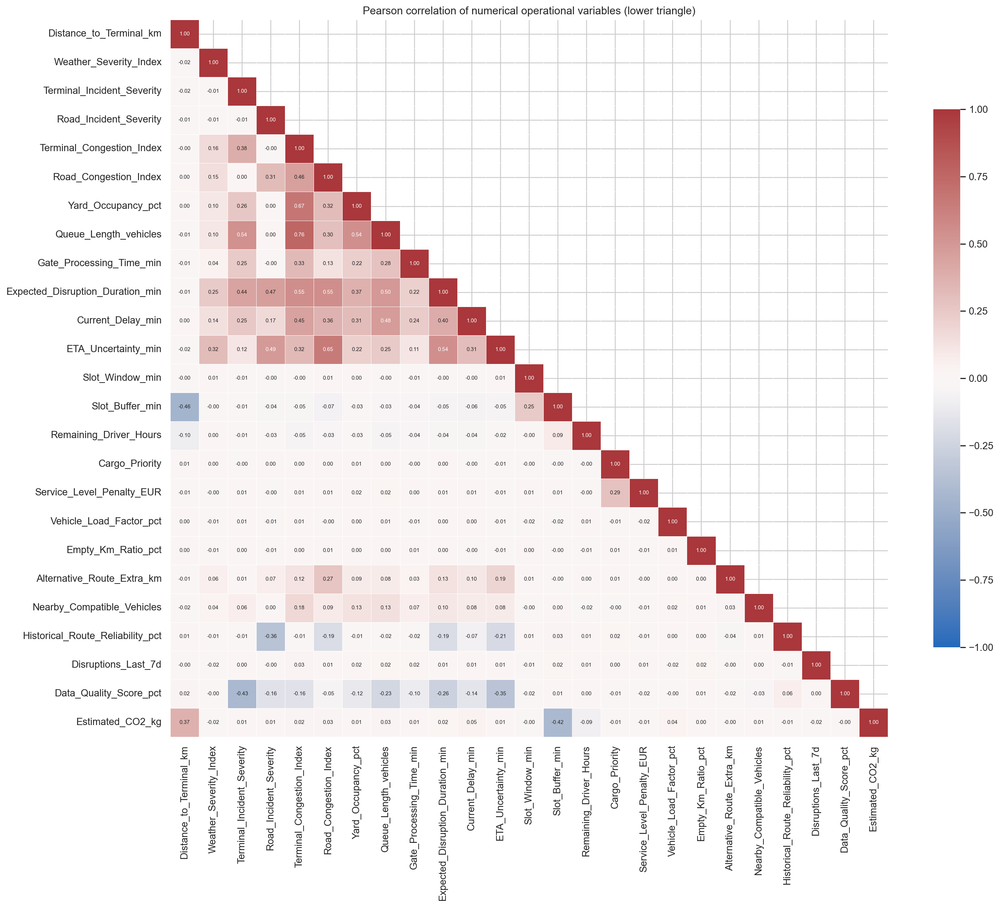

In [21]:
# Pearson correlation with readable annotations; display only the lower triangle.
corr = df[numeric_features].corr(method="pearson", numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(
    corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 6},
    linewidths=0.25, square=True, cbar_kws={"shrink": 0.75}, ax=ax
)
ax.set_title("Pearson correlation of numerical operational variables (lower triangle)")
plt.tight_layout()
show_and_save("13_correlation_heatmap_annotated_lower_triangle")


In [22]:
# Identify strongest absolute correlations for discussion
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .reset_index()
)
corr_pairs.columns = ["feature_1", "feature_2", "pearson_r"]
corr_pairs["abs_r"] = corr_pairs["pearson_r"].abs()
display(corr_pairs.sort_values("abs_r", ascending=False).head(20).round(3))


,feature_1,feature_2,pearson_r,abs_r
92,Terminal_Congestion_Index,Queue_Length_vehicles,0.759,0.759
91,Terminal_Congestion_Index,Yard_Occupancy_pct,0.673,0.673
115,Road_Congestion_Index,ETA_Uncertainty_min,0.654,0.654
94,Terminal_Congestion_Index,Expected_Disruption_Duration_min,0.551,0.551
113,Road_Congestion_Index,Expected_Disruption_Duration_min,0.547,0.547
181,Expected_Disruption_Duration_min,ETA_Uncertainty_min,0.543,0.543
129,Yard_Occupancy_pct,Queue_Length_vehicles,0.539,0.539
51,Terminal_Incident_Severity,Queue_Length_vehicles,0.536,0.536
148,Queue_Length_vehicles,Expected_Disruption_Duration_min,0.496,0.496
76,Road_Incident_Severity,ETA_Uncertainty_min,0.486,0.486


In [23]:
# Compact pair plot implemented with Matplotlib to keep notebook execution responsive.
# It displays all six classes in a stratified sample and does not alter analytical data.
pair_features = [
    "Terminal_Congestion_Index", "Queue_Length_vehicles", "Current_Delay_min"
]
pair_parts = []
for action, group in df.groupby(TARGET, dropna=False):
    pair_parts.append(group.sample(n=min(len(group), 75), random_state=42))
pair_sample = pd.concat(pair_parts, ignore_index=True)
actions = list(pair_sample[TARGET].dropna().unique())
palette = dict(zip(actions, sns.color_palette("tab10", n_colors=len(actions))))

fig, axes = plt.subplots(len(pair_features), len(pair_features), figsize=(12, 11))
for i, ycol in enumerate(pair_features):
    for j, xcol in enumerate(pair_features):
        ax = axes[i, j]
        if i == j:
            for action in actions:
                vals = pair_sample.loc[pair_sample[TARGET] == action, xcol].dropna()
                ax.hist(vals, bins=18, alpha=0.35, label=str(action), color=palette[action])
        else:
            for action in actions:
                sub = pair_sample[pair_sample[TARGET] == action]
                ax.scatter(sub[xcol], sub[ycol], s=12, alpha=0.45,
                           label=str(action), color=palette[action])
        if i == len(pair_features) - 1:
            ax.set_xlabel(xcol.replace("_", " "))
        else:
            ax.set_xlabel("")
        if j == 0:
            ax.set_ylabel(ycol.replace("_", " "))
        else:
            ax.set_ylabel("")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title=TARGET, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle("Pair plot of selected operational variables (stratified display sample)", y=1.02)
fig.tight_layout()
savefig("14_pairplot_selected_operational_variables")
plt.close(fig)


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/14_pairplot_selected_operational_variables.png


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/15_parallel_coordinates.png


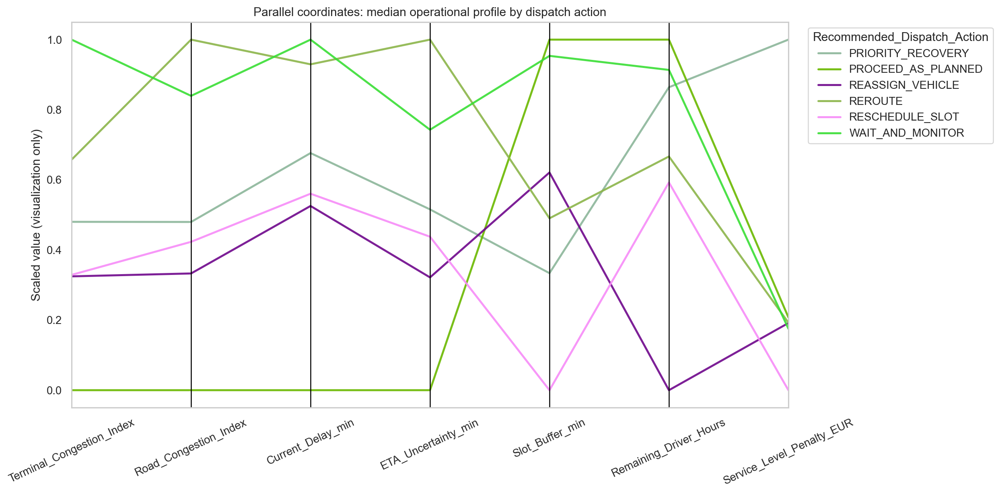

In [24]:
# Parallel coordinates using one median profile per dispatch action.
# This avoids hundreds of overlapping raw-case lines and makes class profiles interpretable.
pc_features = [
    "Terminal_Congestion_Index", "Road_Congestion_Index",
    "Current_Delay_min", "ETA_Uncertainty_min",
    "Slot_Buffer_min", "Remaining_Driver_Hours",
    "Service_Level_Penalty_EUR"
]
pc = df.groupby(TARGET)[pc_features].median().reset_index()

# Robust min-max scaling across action-level medians for visualization only.
pc_scaled = pc.copy()
for col in pc_features:
    lo, hi = df[col].quantile(0.01), df[col].quantile(0.99)
    pc_scaled[col] = pc_scaled[col].clip(lo, hi)
    denom = pc_scaled[col].max() - pc_scaled[col].min()
    pc_scaled[col] = (pc_scaled[col] - pc_scaled[col].min()) / denom if denom else 0.0

plt.figure(figsize=(14, 7))
parallel_coordinates(pc_scaled, TARGET, alpha=0.9, linewidth=2)
plt.title("Parallel coordinates: median operational profile by dispatch action")
plt.ylabel("Scaled value (visualization only)")
plt.xticks(rotation=25)
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("15_parallel_coordinates")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/16_bubble_congestion_delay_penalty.png


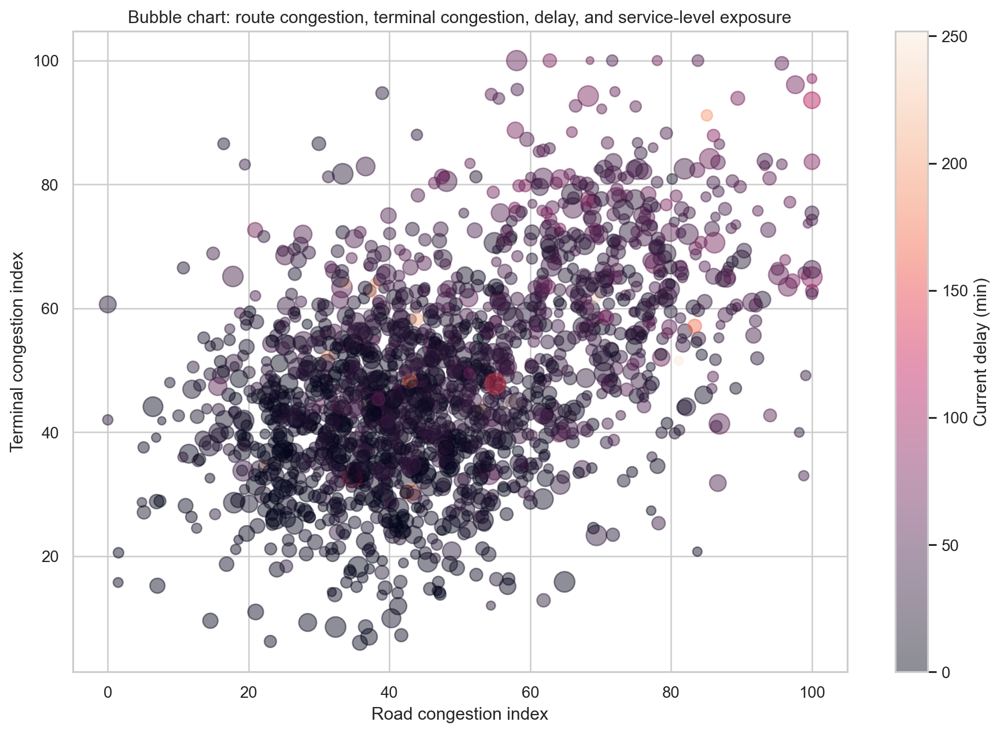

In [25]:
# Bubble chart: road congestion vs terminal congestion,
# bubble size = service-level penalty, color = current delay
bubble = df[[
    "Road_Congestion_Index", "Terminal_Congestion_Index",
    "Service_Level_Penalty_EUR", "Current_Delay_min", TARGET
]].dropna().sample(min(1800, df.dropna().shape[0]), random_state=42)

plt.figure(figsize=(12, 8))
sizes = 20 + 180 * (bubble["Service_Level_Penalty_EUR"] / bubble["Service_Level_Penalty_EUR"].quantile(0.95)).clip(0, 1)
sc = plt.scatter(
    bubble["Road_Congestion_Index"],
    bubble["Terminal_Congestion_Index"],
    s=sizes,
    c=bubble["Current_Delay_min"],
    alpha=0.45
)
plt.colorbar(sc, label="Current delay (min)")
plt.xlabel("Road congestion index")
plt.ylabel("Terminal congestion index")
plt.title("Bubble chart: route congestion, terminal congestion, delay, and service-level exposure")
show_and_save("16_bubble_congestion_delay_penalty")


## 9. Operational relationship analysis by target class

For a classification problem, the most useful EDA questions are often class-conditional:

- Does increasing congestion coincide with a changing action mix?
- Does negative slot buffer correspond to more recovery/rescheduling actions?
- Are technical warnings associated with vehicle reassignment?
- Does low remaining driver time coincide with particular operational responses?
- Does the availability of alternative routes/terminals alter the action distribution?

These are descriptive questions; the notebook does not claim that any feature causes the target.

In [26]:
# Numeric feature distributions summarized by target class
target_numeric_summary = df.groupby(TARGET)[[
    "Terminal_Congestion_Index", "Road_Congestion_Index",
    "Current_Delay_min", "ETA_Uncertainty_min",
    "Slot_Buffer_min", "Remaining_Driver_Hours",
    "Service_Level_Penalty_EUR", "Estimated_CO2_kg"
]].agg(["mean", "median"]).round(2)

display(target_numeric_summary)


Terminal_Congestion_Index         \
                                                 mean median   
Recommended_Dispatch_Action                                    
PRIORITY_RECOVERY                               50.51  48.80   
PROCEED_AS_PLANNED                              40.63  40.89   
REASSIGN_VEHICLE                                47.71  46.24   
REROUTE                                         53.44  51.72   
RESCHEDULE_SLOT                                 48.50  46.31   
WAIT_AND_MONITOR                                56.47  57.36   

                            Road_Congestion_Index        Current_Delay_min  \
                                             mean median              mean   
Recommended_Dispatch_Action                                                  
PRIORITY_RECOVERY                           48.69  46.28             27.83   
PROCEED_AS_PLANNED                          37.93  37.21             12.87   
REASSIGN_VEHICLE                            45.48  43.50             24.44   
REROUTE                                     58.67  56.10             32.04   
RESCHEDULE_SLOT                             47.34  45.20             26.36   
WAIT_AND_MONITOR                            53.13  53.07             32.89   

                                   ETA_Uncertainty_min        Slot_Buffer_min  \
                            median                mean median            mean   
Recommended_Dispatch_Action                                                     
PRIORITY_RECOVERY            23.68               19.30  19.04            7.42   
PROCEED_AS_PLANNED            9.56               16.22  15.93           73.66   
REASSIGN_VEHICLE             20.53               18.11  17.87           33.80   
REROUTE                      28.96               22.78  21.96           26.70   
RESCHEDULE_SLOT              21.26               18.82  18.57          -28.38   
WAIT_AND_MONITOR             30.44               20.40  20.41           73.86   

                                   Remaining_Driver_Hours         \
                            median                   mean median   
Recommended_Dispatch_Action                                        
PRIORITY_RECOVERY             7.96                   4.70   4.71   
PROCEED_AS_PLANNED           72.04                   4.89   4.82   
REASSIGN_VEHICLE             35.58                   3.78   4.01   
REROUTE                      23.01                   4.58   4.55   
RESCHEDULE_SLOT             -24.15                   4.57   4.49   
WAIT_AND_MONITOR             67.58                   4.79   4.75   

                            Service_Level_Penalty_EUR          \
                                                 mean  median   
Recommended_Dispatch_Action                                     
PRIORITY_RECOVERY                              450.63  327.22   
PROCEED_AS_PLANNED                             363.03  270.23   
REASSIGN_VEHICLE                               361.17  269.06   
REROUTE                                        343.53  269.14   
RESCHEDULE_SLOT                                332.72  255.28   
WAIT_AND_MONITOR                               357.79  267.90   

                            Estimated_CO2_kg         
                                        mean median  
Recommended_Dispatch_Action                          
PRIORITY_RECOVERY                      69.35  56.24  
PROCEED_AS_PLANNED                     46.17  36.25  
REASSIGN_VEHICLE                       60.25  48.85  
REROUTE                                61.95  48.24  
RESCHEDULE_SLOT                        81.36  68.69  
WAIT_AND_MONITOR                       44.98  37.66

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/17_mean_operational_conditions_by_action.png


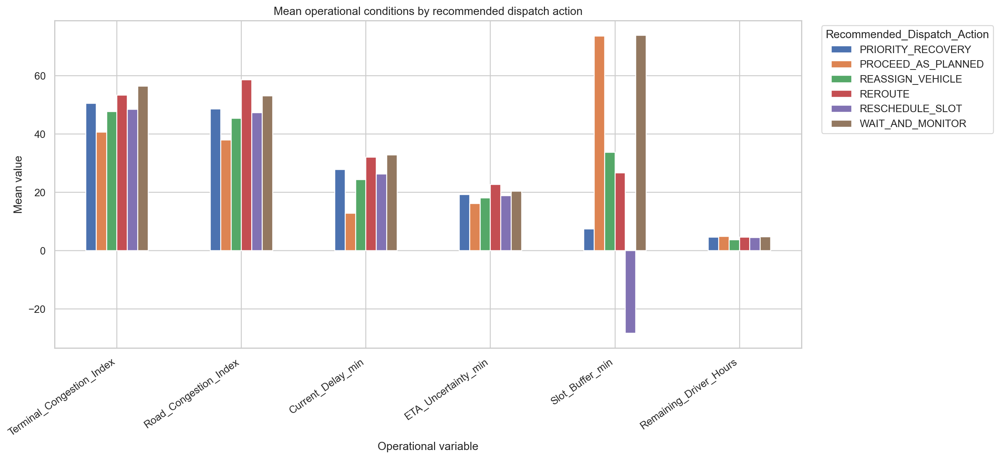

In [27]:
# Mean operational conditions by dispatch action
means = df.groupby(TARGET)[[
    "Terminal_Congestion_Index", "Road_Congestion_Index",
    "Current_Delay_min", "ETA_Uncertainty_min",
    "Slot_Buffer_min", "Remaining_Driver_Hours"
]].mean()

means.T.plot(kind="bar", figsize=(15, 7))
plt.ylabel("Mean value")
plt.xlabel("Operational variable")
plt.title("Mean operational conditions by recommended dispatch action")
plt.xticks(rotation=35, ha="right")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("17_mean_operational_conditions_by_action")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/18_slot_buffer_action_composition.png


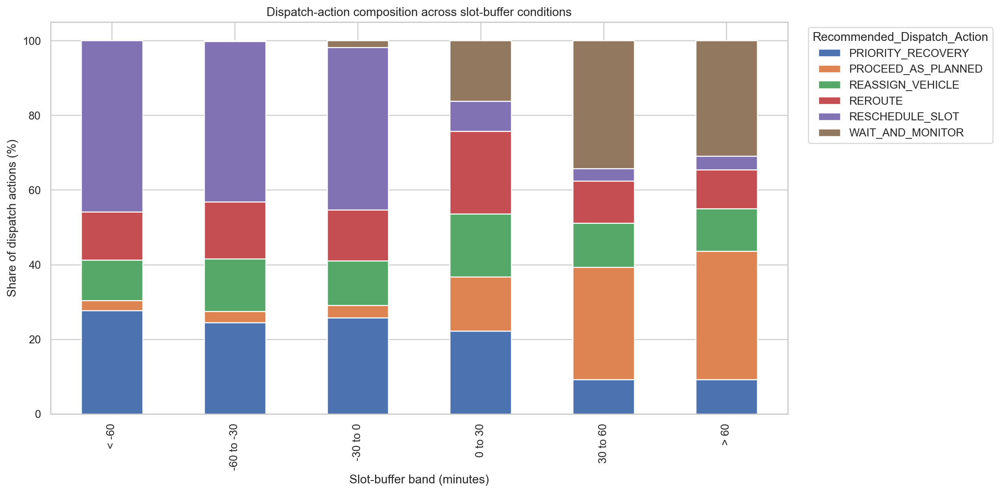

In [28]:
# Slot-buffer bins and dispatch-action composition
df_tmp = df.copy()
df_tmp["Slot_Buffer_Band"] = pd.cut(
    df_tmp["Slot_Buffer_min"],
    bins=[-np.inf, -60, -30, 0, 30, 60, np.inf],
    labels=["< -60", "-60 to -30", "-30 to 0", "0 to 30", "30 to 60", "> 60"]
)

slot_ct = pd.crosstab(
    df_tmp["Slot_Buffer_Band"], df_tmp[TARGET], normalize="index"
) * 100

slot_ct.plot(kind="bar", stacked=True, figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Slot-buffer band (minutes)")
plt.title("Dispatch-action composition across slot-buffer conditions")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("18_slot_buffer_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/19_terminal_congestion_action_composition.png


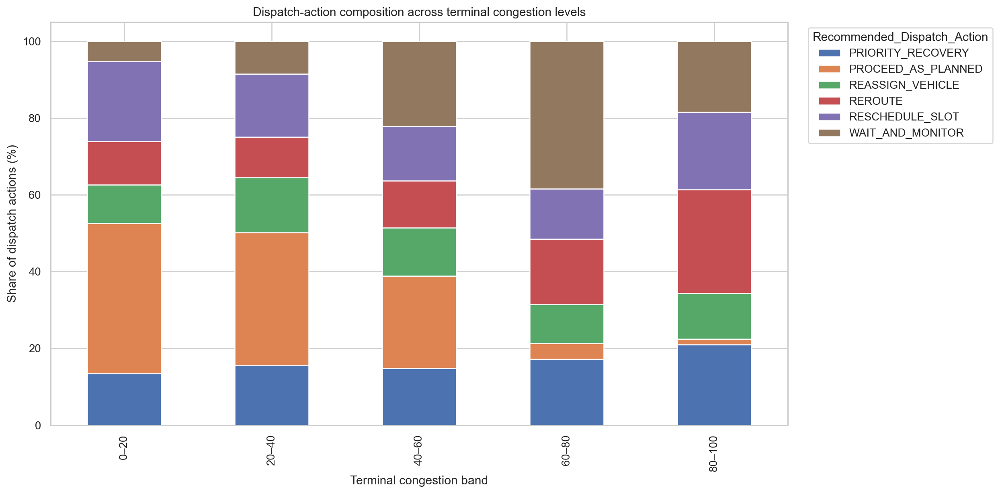

In [29]:
# Congestion bins and action composition
df_tmp["Terminal_Congestion_Band"] = pd.cut(
    df_tmp["Terminal_Congestion_Index"],
    bins=[-np.inf, 20, 40, 60, 80, np.inf],
    labels=["0–20", "20–40", "40–60", "60–80", "80–100"]
)

cong_ct = pd.crosstab(
    df_tmp["Terminal_Congestion_Band"], df_tmp[TARGET], normalize="index"
) * 100

cong_ct.plot(kind="bar", stacked=True, figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Terminal congestion band")
plt.title("Dispatch-action composition across terminal congestion levels")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("19_terminal_congestion_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/20_current_delay_action_composition.png


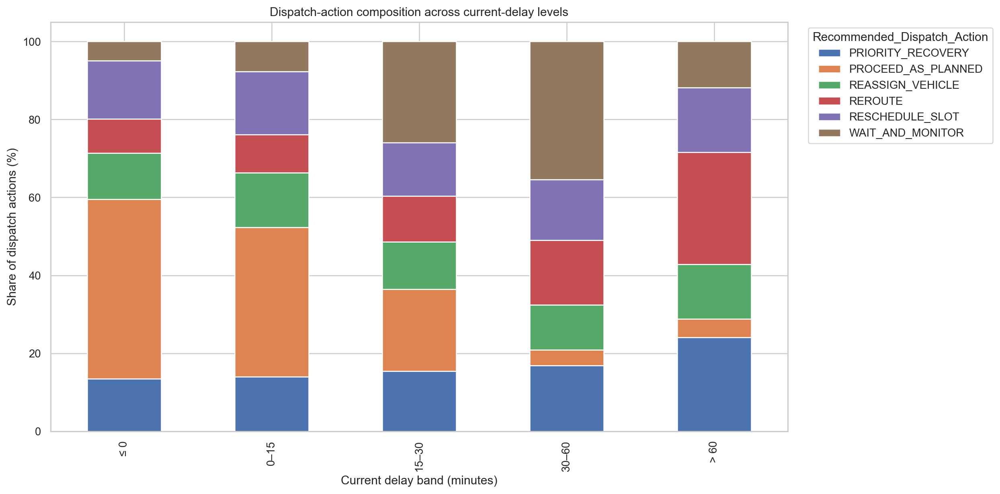

In [30]:
# Delay bins and action composition
df_tmp["Delay_Band"] = pd.cut(
    df_tmp["Current_Delay_min"],
    bins=[-np.inf, 0, 15, 30, 60, np.inf],
    labels=["≤ 0", "0–15", "15–30", "30–60", "> 60"]
)

delay_ct = pd.crosstab(
    df_tmp["Delay_Band"], df_tmp[TARGET], normalize="index"
) * 100

delay_ct.plot(kind="bar", stacked=True, figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Current delay band (minutes)")
plt.title("Dispatch-action composition across current-delay levels")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("20_current_delay_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/21_vehicle_technical_status_action_composition.png


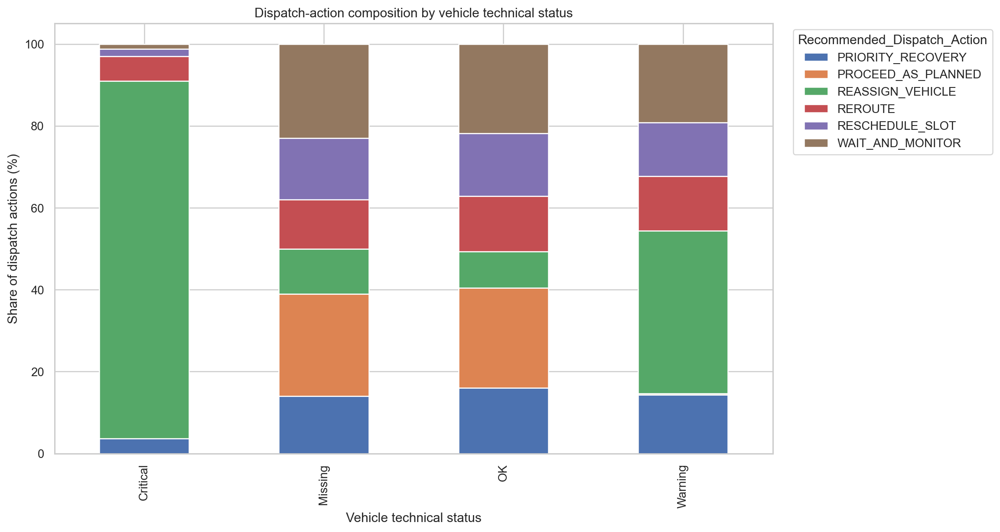

In [31]:
# Technical status vs action
tech_ct = pd.crosstab(
    df["Vehicle_Technical_Status"].fillna("Missing"),
    df[TARGET],
    normalize="index"
) * 100

tech_ct.plot(kind="bar", stacked=True, figsize=(13, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Vehicle technical status")
plt.title("Dispatch-action composition by vehicle technical status")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("21_vehicle_technical_status_action_composition")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/22_alternative_route_action_composition.png


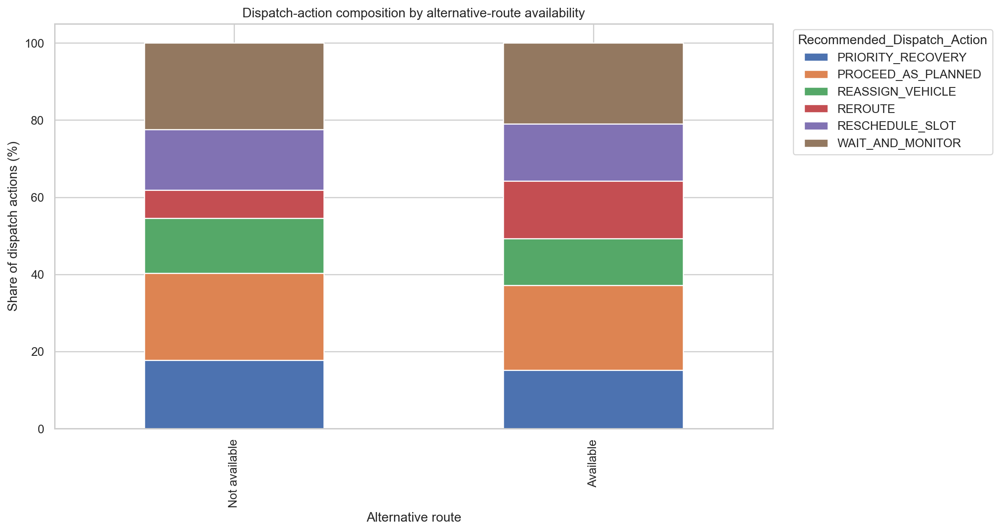

In [32]:
# Alternative-route availability vs action
route_ct = pd.crosstab(
    df["Alternative_Route_Available"].fillna(False),
    df[TARGET],
    normalize="index"
) * 100

route_ct.index = route_ct.index.map({True: "Available", False: "Not available"})
route_ct.plot(kind="bar", stacked=True, figsize=(13, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Alternative route")
plt.title("Dispatch-action composition by alternative-route availability")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("22_alternative_route_action_composition")


## 10. Temporal analysis

`Event_Timestamp` can be transformed into calendar features. The dataset is examined by month and hour to identify possible operational patterns. These are exploratory patterns only; they should not be interpreted as causal effects.

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/23_monthly_case_volume.png


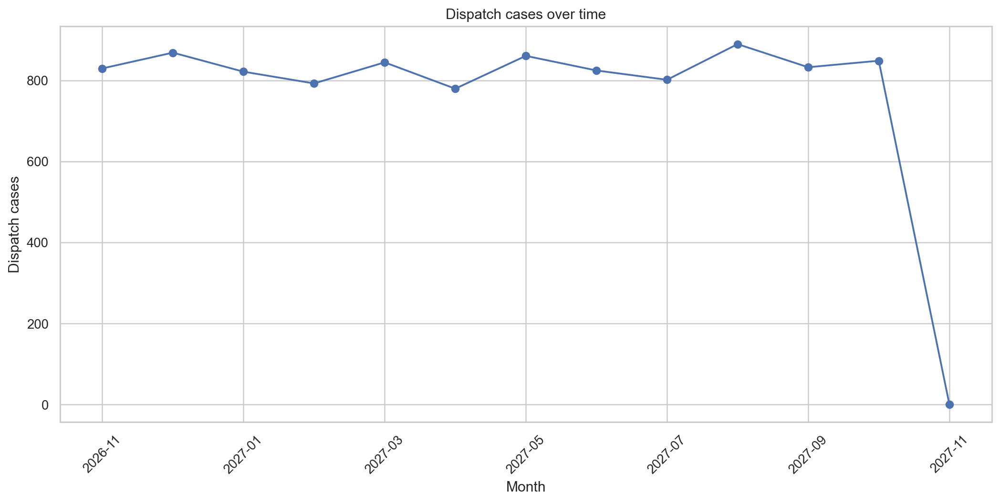

In [33]:
df_time = df.copy()
df_time["Event_Timestamp"] = pd.to_datetime(df_time["Event_Timestamp"], errors="coerce")
df_time["Month"] = df_time["Event_Timestamp"].dt.to_period("M").astype(str)
df_time["Hour"] = df_time["Event_Timestamp"].dt.hour

monthly_counts = df_time.groupby("Month").size()
plt.figure(figsize=(14, 6))
monthly_counts.plot(marker="o")
plt.xlabel("Month")
plt.ylabel("Dispatch cases")
plt.title("Dispatch cases over time")
plt.xticks(rotation=45)
show_and_save("23_monthly_case_volume")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/24_monthly_action_mix.png


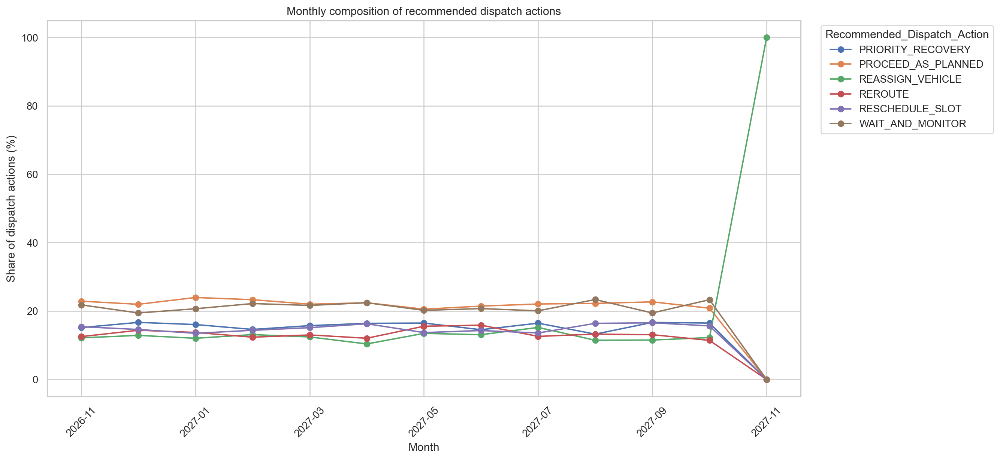

In [34]:
monthly_action = pd.crosstab(
    df_time["Month"], df_time[TARGET], normalize="index"
) * 100

monthly_action.plot(kind="line", marker="o", figsize=(15, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Month")
plt.title("Monthly composition of recommended dispatch actions")
plt.xticks(rotation=45)
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("24_monthly_action_mix")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/25_hourly_action_mix.png


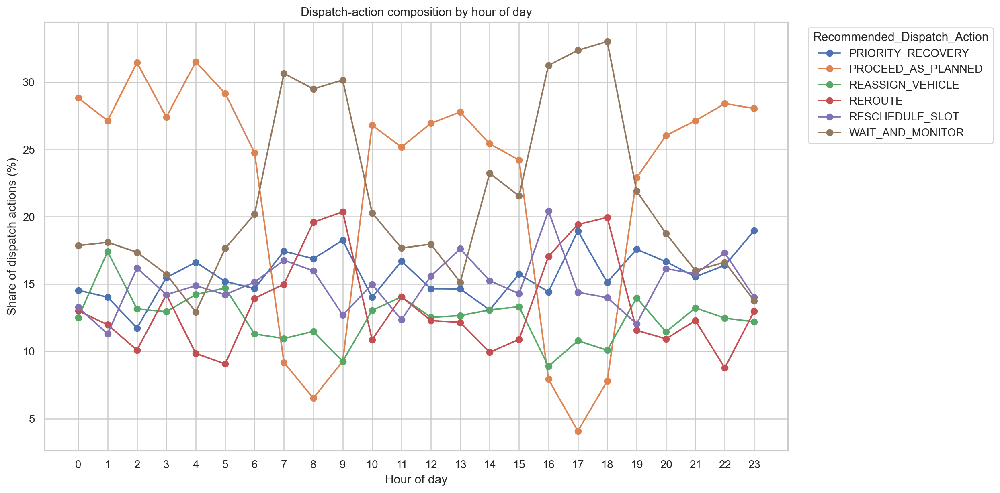

In [35]:
hourly_action = pd.crosstab(
    df_time["Hour"], df_time[TARGET], normalize="index"
) * 100

hourly_action.plot(kind="line", marker="o", figsize=(14, 7))
plt.ylabel("Share of dispatch actions (%)")
plt.xlabel("Hour of day")
plt.title("Dispatch-action composition by hour of day")
plt.xticks(range(0, 24))
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("25_hourly_action_mix")


## 11. Brainstorming: findings, hypotheses, and questions

The brainstorming section translates the EDA into operationally testable ideas. Each statement is linked to a specific table or figure generated above. These are **hypotheses for later investigation**, not claims of causality.

In [36]:
# Automated evidence table for brainstorming
brainstorm_evidence = []

# Class distribution
largest_class = target_counts.idxmax()
smallest_class = target_counts.idxmin()
brainstorm_evidence.append({
    "Evidence": "Target distribution",
    "Observed result": f"{largest_class} is the largest class ({target_counts[largest_class]:,}; {target_pct[largest_class]:.2f}%), while {smallest_class} is the smallest ({target_counts[smallest_class]:,}; {target_pct[smallest_class]:.2f}%).",
    "Reference": "Figure 3 / Figure 4 and target_table"
})

# Missingness
highest_missing_feature = missing_pct.index[0]
brainstorm_evidence.append({
    "Evidence": "Missingness",
    "Observed result": f"{highest_missing_feature} has the highest missing-value rate at {missing_pct.iloc[0]:.2f}%.",
    "Reference": "Figure 1 / Figure 2 and missing_table"
})

# Strongest correlations
strongest = corr_pairs.sort_values("abs_r", ascending=False).iloc[0]
brainstorm_evidence.append({
    "Evidence": "Numeric association",
    "Observed result": f"The strongest absolute Pearson correlation among numeric variables is between {strongest['feature_1']} and {strongest['feature_2']} (r={strongest['pearson_r']:.3f}).",
    "Reference": "Figure 13 and corr_pairs"
})

display(pd.DataFrame(brainstorm_evidence))


,Evidence,Observed result,Reference
0,Target distribution,"PROCEED_AS_PLANNED is the largest class (2,219...",Figure 3 / Figure 4 and target_table
1,Missingness,Alternative_Route_Extra_km has the highest mis...,Figure 1 / Figure 2 and missing_table
2,Numeric association,The strongest absolute Pearson correlation amo...,Figure 13 and corr_pairs


### Brainstorming points

**1. Dispatch actions appear to form a multi-regime operational problem.**  
The corrected 10,000-case analysis contains six distinct operational actions rather than a binary decision. This means later classification analysis should investigate whether each class occupies a distinct operational region or whether several classes overlap substantially.  
**Evidence:** target class-distribution table and bar chart and class-conditional distributions in Figures 10, 17–22.

**2. Slot-buffer conditions are a direct candidate for action differentiation.**  
A negative `Slot_Buffer_min` represents an expected slot miss according to the project definition. Therefore, the action mix across the slot-buffer bands is an important operational diagnostic.  
**Evidence:** Figure 18.  
**Hypothesis:** As slot buffer moves from positive slack toward negative values, recovery-oriented or rescheduling actions may become more prevalent. This must be tested quantitatively rather than assumed.

**3. Congestion should be investigated jointly rather than as a single variable.**  
The project figure explicitly highlights terminal congestion and route conditions. The dataset separately records `Terminal_Congestion_Index` and `Road_Congestion_Index`, allowing the analysis to distinguish terminal-side and corridor-side pressure.  
**Evidence:** Figure 13 correlation heatmap, Figure 16 bubble chart, and Figure 19 terminal-congestion action composition.  
**Question:** Are dispatch actions more strongly differentiated by terminal congestion, road congestion, or their combination?

**4. Delay and ETA uncertainty may provide complementary information.**  
`Current_Delay_min` measures accumulated delay, whereas `ETA_Uncertainty_min` represents uncertainty around the ETA. A dispatch case can therefore have high delay but relatively stable ETA, or lower current delay but substantial uncertainty.  
**Evidence:** Figures 10, 14, 17, and 20.  
**Hypothesis:** The combination of delay and ETA uncertainty may separate monitoring decisions from recovery decisions more clearly than either feature alone.

**5. Vehicle technical status is a natural candidate for vehicle reassignment analysis.**  
The scenario explicitly states that a vehicle can develop a technical warning. The dataset contains `Vehicle_Technical_Status` with operational states such as OK, Warning, and Critical.  
**Evidence:** Figure 21.  
**Question:** Does the action distribution change materially between OK, Warning, and Critical states, and is `REASSIGN_VEHICLE` concentrated in specific states?

**6. Alternative resources create a potentially important decision constraint.**  
The dataset records alternative slots, terminals, routes, compatible vehicles, and driver changes. These variables represent whether the dispatcher has feasible recovery options.  
**Evidence:** Figures 22 and the categorical/boolean analyses.  
**Hypothesis:** The availability of alternatives may distinguish feasible recovery actions from cases that must remain as planned or wait for further information.

**7. Commercial exposure may change the operational priority of a case.**  
`Service_Level_Penalty_EUR` represents synthetic financial exposure if the service commitment is missed. It is therefore relevant to investigate whether high-exposure cases have a different action mix.  
**Evidence:** Figures 10, 14, 16, and 17.  
**Question:** Do high-penalty cases show a greater prevalence of proactive recovery actions after controlling for congestion and delay?

**8. Outliers should be interpreted as potential operational events, not automatically removed.**  
The IQR analysis identifies observations that are unusual relative to the bulk of the sample. In a logistics control-tower setting, extreme congestion, delay, disruption duration, or negative slot buffers may represent meaningful disruption scenarios.  
**Evidence:** Figures 9–12.  
**Methodological support:** NIST recommends investigating unusual observations rather than automatically deleting them.

**9. Temporal patterns may reveal operating regimes.**  
The dataset contains timestamps, shifts, and day-of-week information. Monthly and hourly action-mix plots can reveal whether the synthetic dispatch environment has temporal variation.  
**Evidence:** Figures 23–25.  
**Question:** Are certain dispatch actions concentrated in particular hours or months, and do those differences remain after considering congestion and disruption variables?

**10. Data quality itself should be part of the modeling discussion.**  
The supplied file contains 10,250 rows while the project description states 10,000 cases, and several variables contain missing values. This discrepancy should be documented in the report rather than silently corrected.  
**Evidence:** Section 2 structural checks and missingness tables.  
**Question:** Is the additional 250-row difference intentional in the supplied dataset, or should the group clarify it with the instructor before final modeling?


## 11A. Data-quality review checklist and explicit decisions

### Dataset boundary and provisional record selection

The assignment specifies 10,000 dispatch cases. The CSV contains 10,250 rows and 10,000 unique `Observation_ID` values. The first 10,000 rows form an ordered block with `Observation_ID` values exactly 1 through 10,000, each once. The final 250 rows are appended records whose IDs repeat values in that block. The main EDA therefore uses a **provisional canonical copy of the first 10,000 rows**. This is based on the visible file structure, not random row deletion, and is explicitly subject to instructor/data-owner confirmation.

Of the 250 appended rows, 196 are exact duplicate occurrences in the raw file and 54 contain different non-ID information under an existing ID. The 54 conflicting alternatives are listed in the audit table above; without authoritative source guidance, their validity cannot be independently established. Confirm the provisional first-block rule before final submission. The original `df_raw` is never modified.

### Why the duplicate counts differ

The raw CSV has 196 exact duplicate rows. After trimming whitespace and standardizing category/text formatting across the full file, the duplicate count rises to 229 because some records that were textually different become identical after normalization. These full-file counts describe data quality; **all downstream EDA tables and figures use only the corrected 10,000-row analysis copy**, whose validation checks show one row per ID and no exact duplicate rows.

### Category-label checks

`Day_of_Week`, `Shift`, and `Vehicle_Type` are standardized with explicit maps. Before/after tables show label counts and missingness. All non-empty values in the 10,000-row analysis block should map to the allowed categories; any unresolved label is displayed rather than silently discarded. Original source missing values remain missing.

### Route-distance blanks

The assignment data dictionary states that `Alternative_Route_Extra_km` is blank when no alternative route exists. The final-data cross-tab checks this condition. Matching blanks are treated as not applicable, not zero; contradictory cases are listed for review.

### Remaining uncertainty

The 54 conflicting appended records require instructor/data-owner confirmation. The first-block rule is a transparent provisional analysis choice, not a claim that those alternatives have been authoritatively resolved.


In [37]:
# Duplicate audit on untouched raw data, standardized full data, and final analysis copy.
raw_exact = int(df_raw.duplicated().sum())
standardized_exact = int(df_standardized_all.duplicated().sum())
raw_repeat_occurrences = int(df_raw[ID_COL].duplicated().sum())
standardized_repeat_occurrences = int(df_standardized_all[ID_COL].duplicated().sum())

duplicate_summary = pd.DataFrame({
    "stage": [
        "Supplied raw CSV",
        "Entire file after category/text standardization",
        "Final provisional 10,000-row analysis copy"
    ],
    "rows": [len(df_raw), len(df_standardized_all), len(df)],
    "exact_duplicate_rows_beyond_first": [
        raw_exact, standardized_exact, int(df.duplicated().sum())
    ],
    "repeated_ID_occurrences_beyond_first": [
        raw_repeat_occurrences, standardized_repeat_occurrences, int(df[ID_COL].duplicated().sum())
    ],
    "unique_Observation_IDs": [
        int(df_raw[ID_COL].nunique()), int(df_standardized_all[ID_COL].nunique()), int(df[ID_COL].nunique())
    ]
})
display(duplicate_summary)

print(
    f"Why 196 versus 229? The raw file has {raw_exact} exact duplicate rows. "
    f"After trimming whitespace and standardizing text/categorical labels across the full 10,250-row file, "
    f"{standardized_exact} rows are duplicates. The increase of {standardized_exact - raw_exact} occurs because "
    "some rows that differed only in text formatting become identical after standardization. "
    "Neither full-file count is used as the final EDA denominator; downstream EDA uses the provisional 10,000-row block."
)

# Audit appended rows against the unique-ID block, preserving every raw row for review.
canonical_by_id = first_block.set_index(ID_COL)
extra_records = df_raw.iloc[EXPECTED_CASES:].copy()
extra_records["source_csv_row_1based"] = np.arange(EXPECTED_CASES + 2, len(df_raw) + 2)
extra_records["canonical_csv_row_1based"] = extra_records[ID_COL] + 1
extra_records["record_status"] = "Exact duplicate of an earlier row"
conflict_details = []
for idx, row in extra_records.iterrows():
    obs_id = row[ID_COL]
    base_row = canonical_by_id.loc[obs_id]
    differing = []
    for col in df_raw.columns:
        if col == ID_COL:
            continue
        a, b = row[col], base_row[col]
        equal = (pd.isna(a) and pd.isna(b)) or (not pd.isna(a) and not pd.isna(b) and a == b)
        if not equal:
            differing.append(col)
    if differing:
        extra_records.loc[idx, "record_status"] = "Conflicting same-ID record"
        conflict_details.append({
            "Observation_ID": obs_id,
            "canonical_csv_row_1based": int(obs_id) + 1,
            "extra_csv_row_1based": int(idx) + 2,
            "differing_columns": ", ".join(differing)
        })

conflict_table = pd.DataFrame(conflict_details).sort_values("Observation_ID").reset_index(drop=True)
print(f"Appended records after the 10,000-row block: {len(extra_records):,}")
print("Appended rows exactly matching the canonical block or an earlier record are not added to the analysis.")
print(f"Non-identical same-ID records requiring source/instructor confirmation: {len(conflict_table):,}")
display(conflict_table)

# Explicit decision log: this is a provisional source-structure choice, not a claim that
# the 54 conflicting alternatives have been independently validated.
print(
    "Provisional decision: analyze the first 10,000 rows because they are ordered Observation_ID 1..10,000 "
    "with one row per ID. Exclude the appended 250 rows from EDA. The 54 conflicting same-ID records remain "
    "unresolved alternatives and should be confirmed with the instructor/data owner before final reporting."
)

# Category label audit: report original labels, canonical labels, missingness and unresolved non-empty values.
allowed_categories = {
    "Day_of_Week": set(weekday_map.values()),
    "Shift": set(shift_map.values()),
    "Vehicle_Type": set(vehicle_map.values())
}
category_audit_rows = []
unresolved_label_rows = []
for col, allowed in allowed_categories.items():
    raw_final = first_block[col]
    canonical = df[col]
    raw_nonempty = _normalise_text(raw_final).replace("", pd.NA)
    if col == "Day_of_Week":
        mapped_raw = raw_nonempty.str.lower().map(weekday_map)
    elif col == "Shift":
        mapped_raw = raw_nonempty.str.lower().map(shift_map)
    else:
        mapped_raw = raw_nonempty.str.lower().map(vehicle_map)
    unresolved = sorted(raw_nonempty[mapped_raw.isna() & raw_nonempty.notna()].astype(str).unique().tolist())
    category_audit_rows.append({
        "variable": col,
        "original_nonempty_unique_labels": int(raw_nonempty.nunique(dropna=True)),
        "final_nonmissing_unique_labels": int(canonical.nunique(dropna=True)),
        "missing_before": int(raw_final.isna().sum()),
        "missing_after": int(canonical.isna().sum()),
        "unresolved_nonempty_labels": len(unresolved),
        "final_labels": ", ".join(sorted(canonical.dropna().astype(str).unique()))
    })
    for label in unresolved:
        unresolved_label_rows.append({"variable": col, "unresolved_original_label": label})
display(pd.DataFrame(category_audit_rows))
print("Unresolved non-empty labels (should be empty; genuine source missing values remain missing):")
display(pd.DataFrame(unresolved_label_rows, columns=["variable", "unresolved_original_label"]))


,stage,rows,exact_duplicate_rows_beyond_first,repeated_ID_occurrences_beyond_first,unique_Observation_IDs
0,Supplied raw CSV,10250,196,250,10000
1,Entire file after category/text standardization,10250,229,250,10000
2,"Final provisional 10,000-row analysis copy",10000,0,0,10000


Why 196 versus 229? The raw file has 196 exact duplicate rows. After trimming whitespace and standardizing text/categorical labels across the full 10,250-row file, 229 rows are duplicates. The increase of 33 occurs because some rows that differed only in text formatting become identical after standardization. Neither full-file count is used as the final EDA denominator; downstream EDA uses the provisional 10,000-row block.
Appended records after the 10,000-row block: 250
Appended rows exactly matching the canonical block or an earlier record are not added to the analysis.
Non-identical same-ID records requiring source/instructor confirmation: 54


,Observation_ID,canonical_csv_row_1based,extra_csv_row_1based,differing_columns
0,252,253,10039,Gate_Processing_Time_min
1,417,418,10233,Day_of_Week
2,511,512,10134,Current_Delay_min
3,583,584,10018,Day_of_Week
4,736,737,10165,"Day_of_Week, Shift, Vehicle_Type"
5,1069,1070,10149,Day_of_Week
6,1113,1114,10238,Shift
7,1225,1226,10131,Shift
8,1374,1375,10246,Day_of_Week
9,1510,1511,10247,Vehicle_Type


Provisional decision: analyze the first 10,000 rows because they are ordered Observation_ID 1..10,000 with one row per ID. Exclude the appended 250 rows from EDA. The 54 conflicting same-ID records remain unresolved alternatives and should be confirmed with the instructor/data owner before final reporting.


,variable,original_nonempty_unique_labels,final_nonmissing_unique_labels,missing_before,missing_after,unresolved_nonempty_labels,final_labels
0,Day_of_Week,21,7,100,100,0,"Fri, Mon, Sat, Sun, Thu, Tue, Wed"
1,Shift,9,3,100,100,0,"Day, Evening, Night"
2,Vehicle_Type,15,3,100,100,0,"Rigid_Truck, Swap_Body_Truck, Tractor_Unit"


Unresolved non-empty labels (should be empty; genuine source missing values remain missing):


,variable,unresolved_original_label


### Missing-value treatment plan

Missing values are not automatically imputed during EDA. The analysis denominator is the provisional 10,000-row unique-ID block. `Alternative_Route_Extra_km` is expected to be blank when `Alternative_Route_Available` is false according to the assignment data dictionary. The check below tests this on the final analysis copy. If every blank corresponds to no available route and every available route has a distance, those blanks are described as **not applicable**, not as a value of zero. Any mismatches are listed for investigation. Other missing values remain visible and are not imputed during EDA.


In [38]:
# Recalculate missing counts and percentages using the corrected analysis copy.
missing_counts = df.isna().sum()
missing_plan = pd.DataFrame({
    "variable": df.columns,
    "missing_count": [int(missing_counts[c]) for c in df.columns],
    "missing_pct": [float(missing_counts[c] / len(df) * 100) for c in df.columns],
})
meaning_map = {
    "Alternative_Route_Extra_km": "Expected not-applicable blank when Alternative_Route_Available is False; validate the cross-tab below.",
    TARGET: "Dispatch-action target; preserve as the outcome label.",
    "Event_Timestamp": "Unknown event time; retain missingness and do not fabricate timestamps.",
}
missing_plan["likely_meaning"] = missing_plan["variable"].map(meaning_map).fillna(
    "Value was not recorded or is unavailable; meaning depends on source process."
)
missing_plan["planned_treatment"] = np.where(
    missing_plan["missing_count"].eq(0), "No missing-value treatment needed.",
    np.where(missing_plan["variable"].eq("Alternative_Route_Extra_km"),
             "Keep blank as not applicable only where route is unavailable; investigate mismatches; do not fill with zero.",
             np.where(missing_plan["variable"].eq(TARGET), "Not applicable: target is complete.",
                      "Do not impute during EDA; report and assess semantics before modeling."))
)
display(missing_plan[missing_plan["missing_count"] > 0].sort_values("missing_pct", ascending=False).round(2))

route_missing = df["Alternative_Route_Extra_km"].isna()
route_available = df["Alternative_Route_Available"].astype("boolean")
route_check = pd.DataFrame({
    "condition": [
        "Route unavailable; extra distance missing (expected)",
        "Route unavailable; extra distance present (mismatch)",
        "Route available; extra distance missing (mismatch)",
        "Route available; extra distance present (expected)"
    ],
    "count": [
        int((route_available.eq(False) & route_missing).sum()),
        int((route_available.eq(False) & ~route_missing).sum()),
        int((route_available.eq(True) & route_missing).sum()),
        int((route_available.eq(True) & ~route_missing).sum())
    ]
})
route_check["pct_of_final_dataset"] = (route_check["count"] / len(df) * 100).round(2)
display(route_check)
route_mismatch = (route_available.eq(True) & route_missing) | (route_available.eq(False) & ~route_missing)
route_mismatch_rows = df.loc[route_mismatch, [ID_COL, "Alternative_Route_Available", "Alternative_Route_Extra_km"]]
print(f"Alternative route distance blanks in final data: {int(route_missing.sum()):,} ({route_missing.mean() * 100:.2f}%)")
print(f"Route-availability/distance mismatches requiring investigation: {len(route_mismatch_rows):,}")
display(route_mismatch_rows.head(100))
print(f"Target missing: {int(df[TARGET].isna().sum())}")


,variable,missing_count,missing_pct,likely_meaning,planned_treatment
33,Alternative_Route_Extra_km,2172,21.72,Expected not-applicable blank when Alternative...,Keep blank as not applicable only where route ...
19,ETA_Uncertainty_min,569,5.69,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
14,Yard_Occupancy_pct,457,4.57,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
17,Expected_Disruption_Duration_min,400,4.00,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
18,Current_Delay_min,300,3.00,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
15,Queue_Length_vehicles,300,3.00,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
16,Gate_Processing_Time_min,250,2.50,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
36,Historical_Route_Reliability_pct,202,2.02,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
25,Remaining_Driver_Hours,100,1.00,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...
24,Vehicle_Technical_Status,100,1.00,Value was not recorded or is unavailable; mean...,Do not impute during EDA; report and assess se...


,condition,count,pct_of_final_dataset
0,Route unavailable; extra distance missing (exp...,2172,21.72
1,Route unavailable; extra distance present (mis...,0,0.00
2,Route available; extra distance missing (misma...,0,0.00
3,Route available; extra distance present (expec...,7828,78.28


Alternative route distance blanks in final data: 2,172 (21.72%)
Route-availability/distance mismatches requiring investigation: 0


,Observation_ID,Alternative_Route_Available,Alternative_Route_Extra_km


Target missing: 0


### Numerical skewness and interpretation

Skewness is reported alongside mean and median. Positive skew indicates a longer upper tail; it is a prompt to inspect extreme observations, not proof of erroneous data. For example, `Distance_to_Terminal_km` has a reported maximum near 842.05 km in the supplied review and should be checked against the intended geography and units rather than removed automatically.

In [39]:
num_cols_audit = df.select_dtypes(include=np.number).columns.tolist()
skewness_table = df[num_cols_audit].skew(numeric_only=True).rename("skewness").to_frame()
skewness_table["mean"] = df[num_cols_audit].mean(numeric_only=True)
skewness_table["median"] = df[num_cols_audit].median(numeric_only=True)
skewness_table["min"] = df[num_cols_audit].min(numeric_only=True)
skewness_table["max"] = df[num_cols_audit].max(numeric_only=True)
skewness_table["interpretation"] = np.select(
    [skewness_table["skewness"] > 1, skewness_table["skewness"] < -1],
    ["Strong right skew: inspect upper tail and units.", "Strong left skew: inspect lower tail and bounds."],
    default="No strong skew by the ±1 heuristic; still inspect domain bounds."
)
display(skewness_table.sort_values("skewness", key=lambda s: s.abs(), ascending=False).round(3))

,skewness,mean,median,min,max,interpretation
Service_Level_Penalty_EUR,5.681,368.317,273.080,31.17,4379.12,Strong right skew: inspect upper tail and units.
Estimated_CO2_kg,5.481,58.672,45.520,20.00,649.87,Strong right skew: inspect upper tail and units.
Gate_Processing_Time_min,5.302,22.467,20.730,5.00,151.38,Strong right skew: inspect upper tail and units.
Distance_to_Terminal_km,5.249,73.204,54.890,5.00,842.05,Strong right skew: inspect upper tail and units.
Current_Delay_min,3.698,25.444,21.825,0.00,254.06,Strong right skew: inspect upper tail and units.
Road_Incident_Severity,3.318,0.177,0.000,0.00,3.00,Strong right skew: inspect upper tail and units.
Terminal_Incident_Severity,2.964,0.208,0.000,0.00,3.00,Strong right skew: inspect upper tail and units.
Weather_Severity_Index,1.414,17.177,13.360,0.02,98.01,Strong right skew: inspect upper tail and units.
Expected_Disruption_Duration_min,1.029,21.735,18.485,0.00,116.16,Strong right skew: inspect upper tail and units.
Cargo_Priority,1.012,1.513,1.000,1.00,3.00,Strong right skew: inspect upper tail and units.


### Outlier decisions: keep, investigate, or correct only when confirmed

The 1.5×IQR rule is a screening method. It can flag valid categorical-like numeric values such as `Slot_Window_min` (expected values: 30, 45, 60, and 90 minutes) and zero-inflated incident severity. Such flags are not automatically errors. The table below records a variable-specific review decision.

In [40]:
outlier_decisions = outlier_table.copy()
def _decision(row):
    feature = row["feature"]
    if feature in {"Terminal_Incident_Severity", "Road_Incident_Severity"}:
        return "Investigate distribution; likely zero-inflated/ordinal. Do not treat IQR flags as errors by default."
    if feature == "Slot_Window_min":
        return "Validate against allowed values 30, 45, 60, 90; keep valid values even if IQR-flagged."
    if feature == "Distance_to_Terminal_km":
        return "Investigate maximum and units/geography; correct only with source confirmation."
    return "Investigate extremes and domain bounds; retain unless a source error is confirmed."
outlier_decisions["review_decision"] = outlier_decisions.apply(_decision, axis=1)
display(outlier_decisions[["feature", "Q1", "Q3", "lower_fence", "upper_fence", "outlier_count", "outlier_pct", "review_decision"]].round(3))
print("Observed Slot_Window_min values:", sorted(df["Slot_Window_min"].dropna().unique().tolist()))

,feature,Q1,Q3,lower_fence,upper_fence,outlier_count,outlier_pct,review_decision
2,Terminal_Incident_Severity,0.000,0.000,0.000,0.000,1393,13.93,Investigate distribution; likely zero-inflated...
3,Road_Incident_Severity,0.000,0.000,0.000,0.000,1234,12.34,Investigate distribution; likely zero-inflated...
12,Slot_Window_min,45.000,60.000,22.500,82.500,968,9.68,"Validate against allowed values 30, 45, 60, 90..."
0,Distance_to_Terminal_km,35.440,86.197,-40.696,162.334,583,5.83,Investigate maximum and units/geography; corre...
16,Service_Level_Penalty_EUR,179.230,425.903,-190.779,795.911,576,5.76,Investigate extremes and domain bounds; retain...
24,Estimated_CO2_kg,29.377,68.072,-28.665,126.115,560,5.60,Investigate extremes and domain bounds; retain...
1,Weather_Severity_Index,6.938,23.582,-18.030,48.550,389,3.89,Investigate extremes and domain bounds; retain...
8,Gate_Processing_Time_min,16.530,25.670,2.820,39.380,319,3.19,Investigate extremes and domain bounds; retain...
13,Slot_Buffer_min,-2.710,83.955,-132.708,213.952,238,2.38,Investigate extremes and domain bounds; retain...
22,Disruptions_Last_7d,2.000,4.000,-1.000,7.000,228,2.28,Investigate extremes and domain bounds; retain...


Observed Slot_Window_min values: [30.0, 45.0, 60.0, 90.0]


## 11B. Additional relationship and dispatch-time checks

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/spearman_correlation_lower_triangle.png


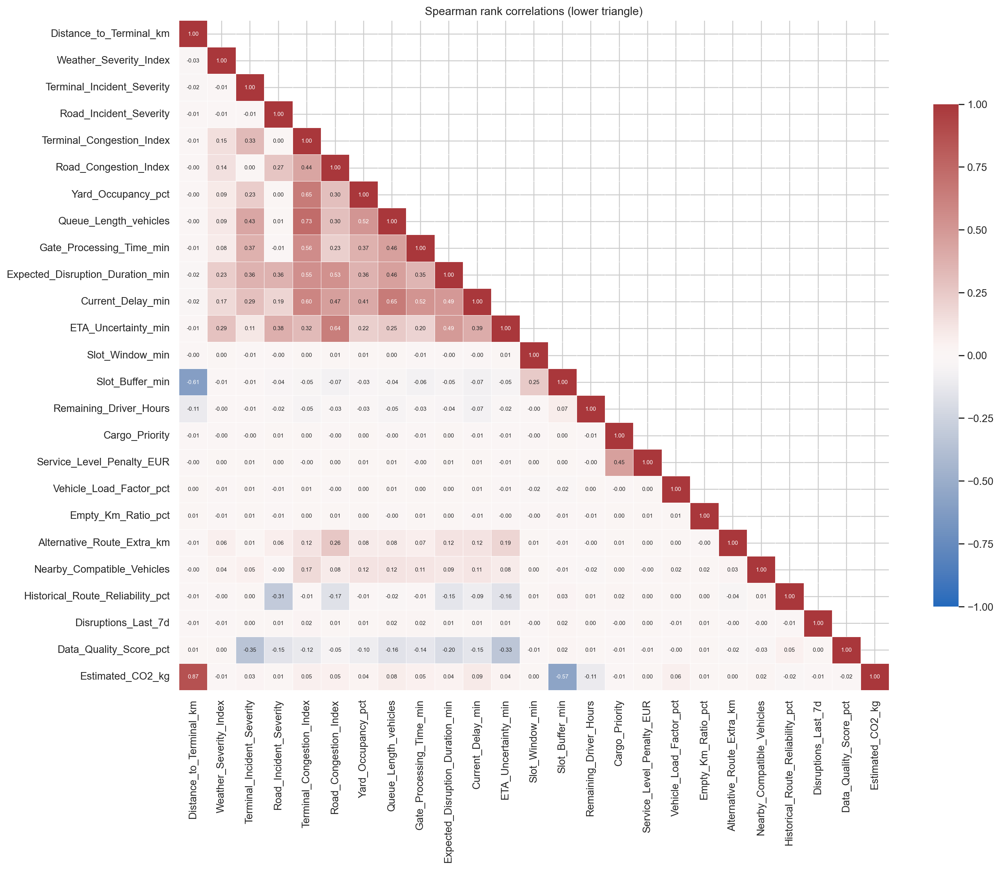

Recommended_Dispatch_Action,PRIORITY_RECOVERY,PROCEED_AS_PLANNED,REASSIGN_VEHICLE,REROUTE,RESCHEDULE_SLOT,WAIT_AND_MONITOR
Expected_Disruption_Duration_min,,,,,,
≤30 min,15.4,29.7,13.5,9.3,15.8,16.3
31–60 min,16.4,5.2,10.9,17.2,12.7,37.6
61–120 min,18.0,1.0,7.7,51.1,15.3,6.9


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/action_percent_by_disruption_duration.png


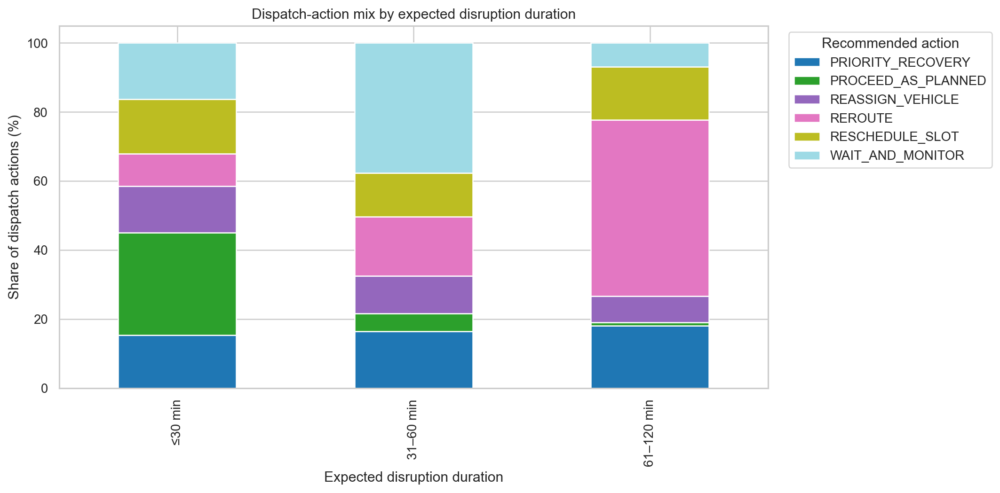

Spearman association between Slot_Buffer_min and Current_Delay_min: -0.075
Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-2-updated/slot_buffer_vs_current_delay.png


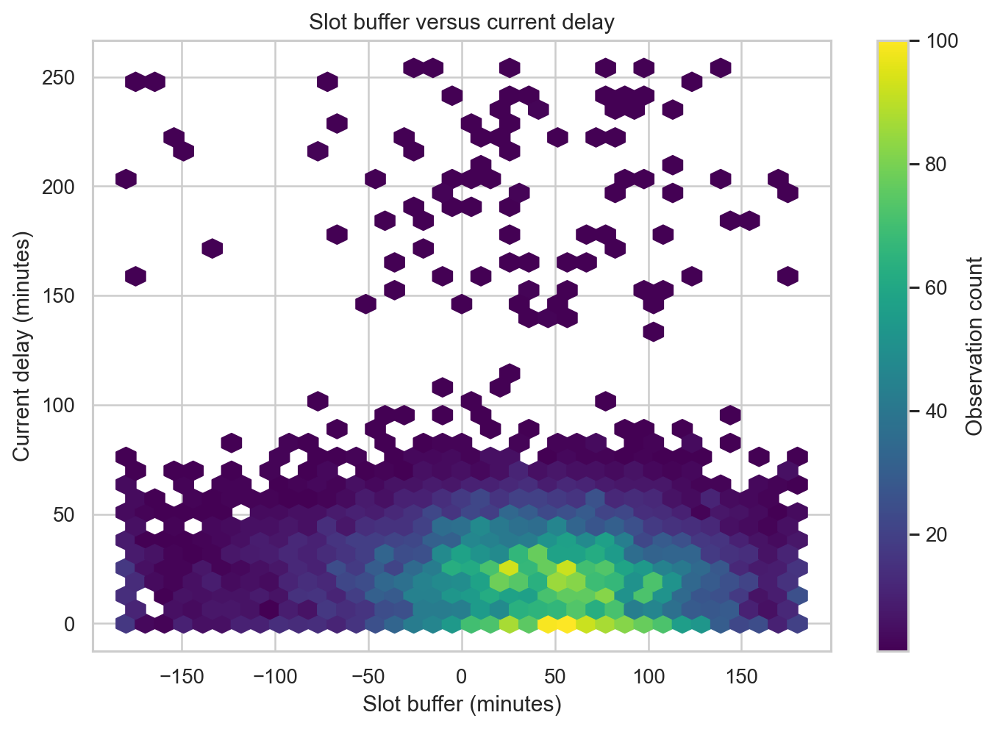

,variable,dispatch_time_check
0,Event_Timestamp,Usually available at dispatch; confirm timesta...
1,Current_Delay_min,Likely available at decision time; confirm mea...
2,Expected_Disruption_Duration_min,Forecast/expectation should be available only ...
3,Alternative_Route_Extra_km,Potentially available when route alternatives ...
4,Estimated_CO2_kg,Potential leakage risk if calculated from the ...
5,Service_Level_Penalty_EUR,Potential leakage risk if penalty is computed ...
6,Recommended_Dispatch_Action,Outcome label; never include as a predictor.


In [41]:
# Spearman rank correlations complement Pearson where relationships may be monotonic but non-linear.
spearman_corr = df[numeric_features].corr(method="spearman", numeric_only=True)
plt.figure(figsize=(16, 13))
sns.heatmap(spearman_corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 6}, mask=np.triu(np.ones_like(spearman_corr, dtype=bool), k=1),
            linewidths=0.2, cbar_kws={"shrink": .75})
plt.title("Spearman rank correlations (lower triangle)")
plt.tight_layout()
show_and_save("spearman_correlation_lower_triangle")

# Duration group vs dispatch-action percentages: quantile groups are robust to skewed durations.
duration = df["Expected_Disruption_Duration_min"]
duration_group = pd.cut(duration, bins=[-np.inf, 30, 60, 120, 240, np.inf],
                        labels=["≤30 min", "31–60 min", "61–120 min", "121–240 min", ">240 min"])
duration_action_pct = pd.crosstab(duration_group, df[TARGET], normalize="index") * 100
display(duration_action_pct.round(1))
ax = duration_action_pct.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="tab20")
ax.set_ylabel("Share of dispatch actions (%)")
ax.set_xlabel("Expected disruption duration")
ax.set_title("Dispatch-action mix by expected disruption duration")
ax.legend(title="Recommended action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_and_save("action_percent_by_disruption_duration")

# Relationship requested in the review: slot buffer versus current delay.
slot_delay = df[["Slot_Buffer_min", "Current_Delay_min"]].dropna()
print("Spearman association between Slot_Buffer_min and Current_Delay_min:",
      round(slot_delay.corr(method="spearman").iloc[0, 1], 3))
plt.figure(figsize=(9, 6))
plt.hexbin(slot_delay["Slot_Buffer_min"], slot_delay["Current_Delay_min"], gridsize=35, mincnt=1, cmap="viridis")
plt.colorbar(label="Observation count")
plt.xlabel("Slot buffer (minutes)")
plt.ylabel("Current delay (minutes)")
plt.title("Slot buffer versus current delay")
show_and_save("slot_buffer_vs_current_delay")

# Dispatch-time availability / potential leakage audit. This is a semantic review, not proof of leakage.
feature_timing = pd.DataFrame([
    ("Event_Timestamp", "Usually available at dispatch; confirm timestamp definition."),
    ("Current_Delay_min", "Likely available at decision time; confirm measurement timing."),
    ("Expected_Disruption_Duration_min", "Forecast/expectation should be available only if estimated before action."),
    ("Alternative_Route_Extra_km", "Potentially available when route alternatives are evaluated; missingness semantics require confirmation."),
    ("Estimated_CO2_kg", "Potential leakage risk if calculated from the final action/route; verify calculation timing."),
    ("Service_Level_Penalty_EUR", "Potential leakage risk if penalty is computed after the action or realized outcome."),
    (TARGET, "Outcome label; never include as a predictor."),
], columns=["variable", "dispatch_time_check"])
display(feature_timing)

## 11C. Evidence-led brainstorming summary

Use the recalculated tables and figures above to prioritize follow-up questions. These are associations and hypotheses, not causal claims.

1. **Class structure:** use the final 10,000-case target distribution and class-conditional charts to assess imbalance and overlap before choosing later evaluation metrics.
2. **Data integrity:** the raw CSV has 10,250 rows, 196 exact duplicate occurrences, and 54 appended non-identical same-ID records. The analysis uses the ordered first 10,000 unique-ID block provisionally; confirm this choice with the instructor.
3. **Category reliability:** inspect the before/after audit for weekday, shift, and vehicle labels. Genuine source missing values are preserved, and unresolved non-empty labels are listed rather than silently converted to missing.
4. **Alternative-route distance:** use the final-data route cross-tab to distinguish expected not-applicable blanks from mismatches. Do not replace not-applicable blanks with zero.
5. **Congestion:** use the recalculated annotated Pearson and Spearman tables to assess the association between `Terminal_Congestion_Index` and `Queue_Length_vehicles`; report the current coefficient from the executed results rather than relying on the older review value.
6. **Duration-dependent actions:** compare action percentages across expected disruption-duration groups and describe differences as associations.
7. **Slot and delay:** examine `Slot_Buffer_min` with `Current_Delay_min`; validate negative buffers and extreme delays against domain definitions.
8. **Leakage review:** verify whether `Estimated_CO2_kg` and `Service_Level_Penalty_EUR` are available at dispatch time or calculated after the action/outcome. If only available afterwards, exclude them from later predictors.


## 12. EDA conclusion

This notebook now reports EDA results from a **provisional 10,000-row analysis copy** rather than treating all 10,250 CSV rows as separate dispatch cases. The first 10,000 rows have sequential, unique `Observation_ID` values from 1 to 10,000; all tables, summary statistics, category charts, distributions, outlier checks, correlations, relationship plots and findings are recalculated from that copy.

The main analytical areas remain congestion, time-window risk, disruption duration, resource constraints, vehicle condition, alternative options, and commercial/sustainability exposure. Interpret the observed relationships as associations, not proof that a feature causes a dispatch action.

**Data-quality caveat before final submission:** the final 250 rows in the supplied CSV are appended repeated-ID records. Of these, 196 are exact duplicate occurrences and 54 contain non-ID differences. The first-block selection is a transparent provisional rule based on the file's ordered unique-ID structure; the 54 conflicting alternatives have not been authoritatively resolved. Confirm the intended record-selection rule with the instructor/data owner. Category mappings and route-distance missingness are explicitly audited; unexpected non-empty labels and route-distance mismatches are listed rather than guessed. The raw CSV is preserved unchanged.

IQR outliers are treated as screening flags, not automatic errors. In particular, incident-severity values can be zero-inflated, and the maximum `Distance_to_Terminal_km` should be checked for units/geographic plausibility but retained unless the source confirms an error. `Recommended_Dispatch_Action` is the target and must never be used as an input feature. `Estimated_CO2_kg` and `Service_Level_Penalty_EUR` remain possible leakage risks until their dispatch-time availability is verified.


## 13. External methodological references

The notebook uses the following external methodological sources to support the EDA approach:

1. **NIST/SEMATECH e-Handbook of Statistical Methods — Exploratory Data Analysis.** NIST describes EDA as an approach for gaining insight, uncovering structure, detecting outliers/anomalies, and using graphical techniques to explore data.
2. **NIST/SEMATECH — Detection of Outliers.** Supports investigating unusual observations rather than automatically treating every outlier as erroneous.
3. **scikit-learn documentation — Imputation of Missing Values.** Provides background on why missing values require explicit preprocessing before many machine-learning estimators.
4. **pandas documentation.** Used as the implementation reference for tabular data handling and missing-value/statistical summaries.

These references support the methodology; the substantive observations in this notebook are derived from the supplied dataset.


### References

- NIST/SEMATECH. *What is Exploratory Data Analysis?* https://www.itl.nist.gov/div898/handbook/eda/section1/eda11.htm
- NIST/SEMATECH. *Exploratory Data Analysis — Detailed Table of Contents.* https://www.itl.nist.gov/div898/handbook/eda/eda_d.htm
- NIST/SEMATECH. *Detection of Outliers.* https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
- NIST/SEMATECH. *The Role of Graphics.* https://www.itl.nist.gov/div898/handbook/eda/section1/eda15.htm
- scikit-learn. *Imputation of Missing Values.* https://scikit-learn.org/stable/modules/impute.html
- pandas documentation. *User Guide.* https://pandas.pydata.org/docs/user_guide/
